# 07 · Construcción y evaluación de modelos

**Términos que se usan en este notebook:** [AUC](../docs/entrega_1/glosario.md) (qué tan bien un puntaje ordena los días que sí tocaron por delante de los que no: 0,5 es azar, 1 es perfecto), [Brier](../docs/entrega_1/glosario.md) (error cuadrático medio entre la probabilidad predicha y lo que ocurrió; menor es mejor), **BSS o Brier skill score** (`1 − Brier(modelo) / Brier(referencia)`: positivo si el modelo se equivoca menos que la referencia, 0 si igual, negativo si más), [calibración](../docs/entrega_1/glosario.md) (si los días en que el modelo dice "30 %" tocaron cerca del 30 % de las veces), [línea base por decil de σ](../docs/entrega_1/glosario.md) (la tasa de toque observada en el entrenamiento para el grupo de volatilidad de la fila; aquí también por k), [tasa de toque](../docs/entrega_1/glosario.md), [ΔAUC](../docs/entrega_1/glosario.md), [bootstrap por bloques de fechas](../docs/entrega_1/glosario.md), [brecha](../docs/entrega_1/glosario.md), [IC](../docs/entrega_1/glosario.md) y [decil](../docs/entrega_1/glosario.md). **SVM** (máquina de vectores de soporte) busca la frontera que mejor separa los días que tocaron de los que no; con kernel *lineal* la frontera es una combinación de las variables y con kernel *RBF* puede curvarse. **Platt** convierte la distancia a la frontera en una probabilidad. Un **árbol de decisión** hace preguntas de sí o no sobre una variable y devuelve la proporción de toques de la hoja a la que llega la fila.

**Objetivo.** Entrenar tres algoritmos del curso (SVM lineal, SVM RBF y árbol poco profundo), elegir entre ellos **solo con la validación** con una regla fijada antes de mirar, reentrenar el ganador, medirlo **una sola vez** en la prueba frente a dos referencias, decidir con la plantilla de inferencia del profesor si aporta algo más que la volatilidad, y explicar con cifras cómo el AUC, el Brier y la calibración se conectan con los KPI del proyecto.

**Punto del enunciado que cubre.** Punto 10 (construcción y evaluación de modelos). La partición y la brecha son las del notebook 06 y las variables las del 05.

**Qué alimenta.** El modelo ganador se guarda en `app/modelo/` (`modelo.joblib` y `metadata.json`) y lo carga la API; las cifras quedan en `data/resultados/nb07.json`.

**Qué es lo nuevo frente a la entrega 1.** El nivel que fija el usuario llega como **k** (cuántas volatilidades del horizonte bajo el precio está el nivel), así que el modelo recibe k como variable y la tabla apila la etiqueta para k = 0,5, 1, 1,5 y 2. La tasa de toque cambia muchísimo con k; por eso la **tasa constante** es una referencia muy fácil de superar y la comparación exigente es la **línea base decil × k**.

**Contenido.** §1 datos y referencias · §2 grillas y validación año por año · §3 las referencias en validación · §4 selección · §5 reentrenamiento y prueba · §6 decisión frente a la línea base (plantilla del profesor) · §7 calibración · §8 puente con los KPI y cálculo de valor · §9 evaluación cualitativa · §10 modelo guardado · §11 resultados.

## 1. Datos y referencias

La tabla es la del notebook 05, reconstruida con las mismas funciones. La partición se asigna sobre la tabla **completa** antes de filtrar (la brecha se cuenta sobre el calendario completo); `asignar_conjunto` no marca las censuradas, así que se separan con `censurada` y no entran en ningún conjunto. Un modelo se entrena con una **submuestra** del entrenamiento (una fila cada 5 sesiones por acción y k: el SVM RBF se vuelve entrenable y las filas se solapan menos) y se evalúa con **todas** las filas de validación o prueba.

Hay tres referencias, todas calculadas **solo con el entrenamiento** (con todas sus filas, no con la submuestra: así son más estables y no tocan la prueba) (con las filas de 2009–2018 cuando se reentrena para la prueba): (a) la **tasa constante** (un solo número), (b) la **línea base decil × k** (la tasa de toque por decil de σ252 y por k; si una celda queda vacía se usa la tasa de su k y se reporta), y (c) las cifras de la entrega 1 (AUC 0,591 y tasa 0,1839), que se citan solo para contrastar porque son **otra partición**.

In [1]:
import json, sys, time, warnings, itertools, subprocess, tempfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
import joblib, sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_auc_score
# sklearn 1.9.1 (fijada en uv.lock) avisa que el parámetro `probability` de SVC quedará obsoleto; el aviso no cambia
# ninguna cifra y la versión no cambia mientras uv.lock la fije.
warnings.filterwarnings("ignore", category=FutureWarning, message=".*probability.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)

# --- Constantes de esta tarea: se escriben ANTES de mirar la validación y no se tocan después ---
GRILLA_LINEAL = {"C": [0.01, 0.1, 1, 10]}                                    # 4 combinaciones
GRILLA_RBF    = {"C": [0.1, 1, 10], "gamma": [0.01, 0.1, 1]}                 # 9
GRILLA_ARBOL  = {"max_depth": [2, 3, 4, 5], "min_samples_leaf": [500, 2000]}   # 8
GRILLAS = {"arbol": GRILLA_ARBOL, "lineal": GRILLA_LINEAL, "rbf": GRILLA_RBF}
NOMBRE = {"arbol": "Árbol", "lineal": "SVM lineal", "rbf": "SVM RBF"}
RANGO_SIMPLICIDAD = {"arbol": 0, "lineal": 1, "rbf": 2}                       # orden de la regla de selección: árbol → lineal → RBF
TAU_REJILLA = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]                      # solo para el cálculo de valor (reporte)
RAZON_BC = [0.5, 1.0, 1.5, 2.0, 3.0]                                          # beneficio / costo
UMBRAL_DAUC = 0.03                                                            # fila "SVM: umbral" de 04_enfoque_analitico.md §4.5
ALFA = 0.05
KS = [str(k) for k in cm.K_GRID]                                              # claves de k en los JSON: "0.5", "1.0", "1.5", "2.0"
BLOQUE_SUB = 20                                                               # bloque para un año o un subperíodo: 20 fechas (un mes bursátil) deja ~12 bloques por año; con 60 solo caben ~4
SUBPERIODOS = {"2010–2012": (2009, 2012), "2013–2019": (2013, 2019), "2020–2021": (2020, 2021), "2022+": (2022, 2100)}
fm = lambda n: f"{n:,}".replace(",", " ")      # miles con espacio, como en el texto
res = {}                                        # cifras que se guardan en data/resultados/nb07.json
T0 = time.time()
cm.DIR_MODELO.mkdir(parents=True, exist_ok=True)

In [2]:
def jdefault(o):                               # numpy → tipos de JSON
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return None if np.isnan(o) else float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

def armar(alg, pesos="balanced", **hp):
    """Pipeline = escalado (z-score con la media y la desviación del ENTRENAMIENTO) + modelo.
    `pesos="balanced"` pondera cada clase al revés de su frecuencia en los SVM (solo el diagnóstico de §4 usa pesos=None)."""
    if alg == "arbol":
        m = DecisionTreeClassifier(max_depth=hp["max_depth"], min_samples_leaf=hp["min_samples_leaf"], random_state=cm.SEMILLA)
    elif alg == "lineal":
        m = SVC(kernel="linear", C=hp["C"], class_weight=pesos, probability=True, random_state=cm.SEMILLA)
    else:
        m = SVC(kernel="rbf", C=hp["C"], gamma=hp["gamma"], class_weight=pesos, probability=True, random_state=cm.SEMILLA)
    return Pipeline([("escala", StandardScaler()), ("modelo", m)])

def combinaciones(alg):
    g = GRILLAS[alg]
    return [dict(zip(g, v)) for v in itertools.product(*g.values())]

def cid(alg, hp):                              # identificador legible de una combinación
    return alg + "|" + ",".join(f"{k}={v}" for k, v in hp.items())

def auc(y, p):                                 # AUC; vacía si el conjunto tiene una sola clase
    y = np.asarray(y)
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else np.nan

def brier(y, p):
    return float(np.mean((np.asarray(p, dtype=float) - np.asarray(y, dtype=float)) ** 2))

def metricas(df, col, p0, ref="p_base"):
    """AUC, Brier, BSS frente a la tasa constante p0 y BSS frente a la línea base decil × k."""
    y, p = df["y"].to_numpy(), df[col].to_numpy()
    return {"auc": auc(y, p), "brier": brier(y, p), "bss": cm.brier_skill(y, p, p0),
            "bss_vs_base": cm.brier_skill(y, p, df[ref].to_numpy())}

In [3]:
# La partición se asigna sobre la tabla COMPLETA (antes de filtrar): la brecha se cuenta sobre el calendario completo.
# `asignar_conjunto` no excluye las censuradas; se separan con `censurada`.
precios = cm.cargar_snapshot("precios_diarios")
precios = precios[precios.ticker.isin(cm.tickers())].copy()       # la instantánea trae además SPY y XLP
precios["fecha"] = precios["fecha"].astype("datetime64[ns]")
assert precios.ticker.nunique() == 21
tabla = cm.tabla_modelo(cm.construir_panel_diario(precios))
tabla["conjunto"] = cm.asignar_conjunto(tabla["fecha"])                    # entrenamiento / validación / prueba / brecha
tabla["conjunto_final"] = cm.asignar_conjunto(tabla["fecha"], final=True)  # para el reentrenamiento con 2009–2018
n_cens = int(tabla.censurada.sum())
tabla = tabla[~tabla.censurada].copy()                                     # las censuradas no entran en ningún conjunto
tabla["anio"] = tabla["fecha"].dt.year
print(f"tickers: {tabla.ticker.nunique()} · filas no censuradas: {fm(len(tabla))} · censuradas excluidas: {fm(n_cens)}")
print("filas por conjunto (no censuradas):")
print(tabla.groupby("conjunto").size().reindex(["entrenamiento", "validacion", "prueba", "brecha"]).to_string())

ent = tabla[tabla.conjunto == "entrenamiento"]
ent_sub = cm.submuestra(ent)                                               # una fila cada 5 sesiones por ticker y k
VARS = cm.VARIABLES
print(f"\nentrenamiento: {fm(len(ent))} filas · submuestra de entrenamiento: {fm(len(ent_sub))} filas (≈ 1/{len(ent)/len(ent_sub):.2f}) · variables: {VARS}")
res["filas"] = {"por_conjunto": tabla.groupby("conjunto").size().to_dict(), "censuradas_excluidas": n_cens,
                "entrenamiento": len(ent), "submuestra_entrenamiento": len(ent_sub)}

tickers: 21 · filas no censuradas: 349 608 · censuradas excluidas: 5 040
filas por conjunto (no censuradas):
conjunto
entrenamiento    100632
validacion        79464
prueba           159432
brecha            10080

entrenamiento: 100 632 filas · submuestra de entrenamiento: 20 160 filas (≈ 1/4.99) · variables: ['abs_r', 'sigma20_sigma252', 'sigma252', 'k']


In [4]:
def ajustar_referencias(fit):
    """Las referencias se calculan SOLO con las filas `fit` (el entrenamiento correspondiente; nunca con la evaluación)."""
    p0 = float(fit["y"].mean())                                             # (a) tasa constante: un escalar
    cortes = np.quantile(fit["sigma252"], np.linspace(0, 1, cm.DECILES_SIGMA + 1))
    cortes[0], cortes[-1] = -np.inf, np.inf                                 # extremos abiertos: una fila nueva siempre cae en algún decil
    dec = pd.cut(fit["sigma252"], cortes, labels=False).to_numpy()
    tasa_k = fit.groupby("k")["y"].mean()                                   # tasa por k, para completar celdas vacías
    cel = fit.assign(decil=dec).groupby(["decil", "k"])["y"].agg(["mean", "size"])
    tab = cel["mean"].unstack("k").reindex(index=range(cm.DECILES_SIGMA), columns=list(cm.K_GRID))
    n = cel["size"].unstack("k").reindex(index=range(cm.DECILES_SIGMA), columns=list(cm.K_GRID)).fillna(0)
    vacias = int(tab.isna().sum().sum())                                    # decil × k sin filas: se usa la tasa del k (se reporta)
    ceros = int((tab == 0).sum().sum())                                     # ceros OBSERVADOS (hay filas y ninguna tocó): se conservan
    tab = tab.apply(lambda c: c.fillna(tasa_k[c.name]))
    return {"p0": p0, "cortes": cortes, "tab": tab, "n": n, "tasa_k": tasa_k, "vacias": vacias, "ceros": ceros}   # (b) línea base decil × k

def p_base(df, ref):
    """Predicción de la línea base: tasa del entrenamiento en el decil de σ252 de la fila y en su k."""
    dec = pd.cut(df["sigma252"], ref["cortes"], labels=False).to_numpy().astype(int)
    kk = np.searchsorted(cm.K_GRID, df["k"].to_numpy())
    return ref["tab"].to_numpy()[dec, kk]

ref_ent = ajustar_referencias(ent)
p0 = ref_ent["p0"]
print(f"(a) tasa constante del entrenamiento: p0 = {p0:.4f} (todas las filas y todos los k apilados)")
print("    tasa de toque por k en el entrenamiento:", {str(k): round(v, 4) for k, v in ref_ent["tasa_k"].items()})
print(f"(b) línea base decil × k: cortes de σ252 (9 interiores): {np.round(ref_ent['cortes'][1:-1], 5).tolist()}")
print(f"    celdas decil × k vacías: {ref_ent['vacias']} de {ref_ent['tab'].size} · ceros observados: {ref_ent['ceros']} · filas por celda: mín {int(ref_ent['n'].to_numpy().min())}")
print(ref_ent["tab"].round(4).to_string())
print(f"(c) entrega 1 (otra partición, solo para contrastar): AUC de la línea base por decil en la prueba = "
      f"{json.load(open(cm.DIR_RESULTADOS / 'nb04_p4.json'))['auc_base_decil_prueba']:.3f}; tasa de toque (k = 1) = 0,1839 (entrenamiento ≤ 2018, nb04 §4.4)")
print(f"    aquí, k = 1 con el entrenamiento 2010–2014: {ref_ent['tasa_k'][1.0]:.4f}")
res["referencias_entrenamiento"] = {"tasa_constante": p0, "tasa_por_k": {str(k): v for k, v in ref_ent["tasa_k"].items()},
                                    "celdas_vacias": ref_ent["vacias"], "ceros_observados": ref_ent["ceros"]}

(a) tasa constante del entrenamiento: p0 = 0.1435 (todas las filas y todos los k apilados)
    tasa de toque por k en el entrenamiento: {'0.5': 0.3858, '1.0': 0.1404, '1.5': 0.0397, '2.0': 0.0081}
(b) línea base decil × k: cortes de σ252 (9 interiores): [0.00841, 0.00899, 0.00948, 0.00996, 0.01036, 0.01109, 0.0121, 0.01333, 0.01601]
    celdas decil × k vacías: 0 de 40 · ceros observados: 1 · filas por celda: mín 2515
k      0.5000  1.0000  1.5000  2.0000
decil                                
0      0.4658  0.2107  0.0612  0.0095
1      0.4344  0.1959  0.0489  0.0079
2      0.3955  0.1053  0.0254  0.0028
3      0.4583  0.1713  0.0413  0.0068
4      0.3638  0.1157  0.0298  0.0095
5      0.3311  0.0942  0.0195  0.0024
6      0.3839  0.1582  0.0493  0.0095
7      0.3120  0.0711  0.0143  0.0000
8      0.3435  0.1750  0.0847  0.0258
9      0.3700  0.1061  0.0231  0.0072
(c) entrega 1 (otra partición, solo para contrastar): AUC de la línea base por decil en la prueba = 0.591; tasa de toque (

**Lectura.** Quedan 21 acciones y 349 608 filas no censuradas (se excluyen 5 040 censuradas): 100 632 de entrenamiento, 79 464 de validación y 159 432 de prueba, más 10 080 que la brecha descarta. La submuestra de entrenamiento tiene 20 160 filas (una de cada 4,99). Las referencias muestran lo más importante del problema: la tasa de toque del entrenamiento es de 0,1435 en total, pero cambia muchísimo con k: 0,3858 con k = 0,5, 0,1404 con k = 1, 0,0397 con k = 1,5 y 0,0081 con k = 2. **Casi todo lo que hay que saber para predecir "toca el nivel" está en qué tan lejos queda el nivel (k)**, y por eso la tasa constante será una referencia fácil de superar. La línea base decil × k tiene 40 celdas, ninguna vacía (la menor tiene 2 515 filas) y un solo cero observado (decil 8 con k = 2: hay filas y ninguna tocó, así que se conserva como 0). Dentro de cada k la tasa no sube de forma ordenada con σ252 (con k = 1 va de 0,2107 en el primer decil a 0,1061 en el último): como k ya mide el nivel en unidades de σ, la volatilidad por sí sola agrega poca información. Contraste con la entrega 1 (otra partición, k = 1 sin apilar): AUC 0,591 y tasa 0,1839; aquí la tasa de k = 1 es 0,1404 con el entrenamiento 2010–2014, y el AUC no es comparable porque ahora se apilan los 4 k.

## 2. Grillas y validación año por año

Cada algoritmo tiene una grilla de hiperparámetros **fijada antes de mirar la validación** (en la primera celda): SVM lineal con 4 valores de `C` (qué tanto se castigan los errores de entrenamiento: `C` pequeño = frontera más suave), SVM RBF con 3 × 3 valores de `C` y `gamma` (`gamma` grande = frontera más curva), y árbol con profundidad 2 a 5 y hojas de al menos 500 o 2 000 filas (un árbol poco profundo y de hojas grandes es legible y evita memorizar). Son 21 combinaciones. Cada una se entrena una vez con el entrenamiento y se evalúa en cada año de validación (2015–2018). Las probabilidades salen de `SVC(probability=True)` (Platt) o de la proporción de la hoja (árbol).

**Por qué los SVM llevan `class_weight="balanced"`.** Solo 14 % de las filas son "toca" y las dos clases se traslapan mucho. Un SVM sin ponderar prefiere la solución trivial de decir "nunca toca" (así se equivoca poco en el 86 % de las filas) y su frontera queda plana. Ponderar las clases (cada error en la clase rara pesa más) es el tratamiento estándar del desbalance y pone a los SVM en igualdad de condiciones con el árbol; Platt sigue convirtiendo el puntaje de la frontera en una probabilidad. La celda de diagnóstico de §4 muestra el antes y el después.

La métrica de selección es el **BSS frente a la tasa constante del entrenamiento**, calculado por año y promediado (los 4 años). Se reporta por año porque, como mostró el notebook 06, la tasa de toque de cada año es distinta (régimen de volatilidad) y un promedio global escondería cuál año sostiene el resultado. También se muestran el AUC (sobre todas las filas, los 4 k apilados) y el BSS frente a la línea base decil × k, que mide el aporte sobre la volatilidad.

*Tiempo.* Los SVM con `probability=True` son lentos (el ajuste y la predicción sobre ~79 000 filas toman de segundos a medio minuto por combinación); el tiempo total del notebook se declara al final (§11).

In [5]:
val = tabla[tabla.conjunto == "validacion"]
Xtr, ytr = ent_sub[VARS], ent_sub["y"].astype(int)
# Todas las predicciones se calculan UNA vez y se guardan; métricas y bootstraps leen de este DataFrame.
pv = val[["fecha", "ticker", "k", "y", "sigma252", "anio"]].copy()
pv["p_const"] = p0
pv["p_base"] = p_base(val, ref_ent)
combos = []
for alg in GRILLAS:
    for hp in combinaciones(alg):
        t0 = time.time()
        mod = armar(alg, **hp).fit(Xtr, ytr)
        pv[cid(alg, hp)] = mod.predict_proba(val[VARS])[:, 1]
        por_anio = {str(a): cm.brier_skill(g["y"], g[cid(alg, hp)], p0) for a, g in pv.groupby("anio")}
        por_anio_b = {str(a): cm.brier_skill(g["y"], g[cid(alg, hp)], g["p_base"].to_numpy()) for a, g in pv.groupby("anio")}
        combos.append({"algoritmo": alg, "hiperparametros": hp, "id": cid(alg, hp), "bss_por_anio": por_anio,
                       "bss_medio": float(np.mean(list(por_anio.values()))), "auc": auc(pv["y"], pv[cid(alg, hp)]),
                       "bss_vs_linea_base_por_anio": por_anio_b, "bss_vs_linea_base_medio": float(np.mean(list(por_anio_b.values()))),
                       "segundos": round(time.time() - t0, 1)})
print(f"{len(combos)} combinaciones entrenadas con la submuestra de entrenamiento y evaluadas con las {fm(len(val))} filas de validación")
anios = [str(a) for a in cm.ANIOS_VALIDACION]
tasa_val = {str(a): float(g["y"].mean()) for a, g in pv.groupby("anio")}
print("\ntasa de toque de validación por año (todas las filas):", {a: round(v, 4) for a, v in tasa_val.items()})
for alg in GRILLAS:
    t = pd.DataFrame([{**c["hiperparametros"], **{f"BSS {a}": c["bss_por_anio"][a] for a in anios}, "BSS medio": c["bss_medio"],
                       "AUC": c["auc"], "BSS vs base (medio)": c["bss_vs_linea_base_medio"], "s": c["segundos"]}
                      for c in combos if c["algoritmo"] == alg])
    print(f"\n{NOMBRE[alg]} ({len(t)} combinaciones): BSS = 1 − Brier(modelo)/Brier(tasa constante p0 = {p0:.4f})")
    print(t.to_string(index=False))
res["grillas"] = {alg: [{k: c[k] for k in ("hiperparametros", "bss_por_anio", "bss_medio", "auc", "bss_vs_linea_base_por_anio",
                                          "bss_vs_linea_base_medio")} for c in combos if c["algoritmo"] == alg] for alg in GRILLAS}
res["tasa_toque_validacion_por_anio"] = tasa_val

21 combinaciones entrenadas con la submuestra de entrenamiento y evaluadas con las 79 464 filas de validación

tasa de toque de validación por año (todas las filas): {'2015': 0.2235, '2016': 0.1564, '2017': 0.1823, '2018': 0.285}

Árbol (8 combinaciones): BSS = 1 − Brier(modelo)/Brier(tasa constante p0 = 0.1435)
 max_depth  min_samples_leaf  BSS 2015  BSS 2016  BSS 2017  BSS 2018  BSS medio    AUC  BSS vs base (medio)      s
         2               500    0.2073    0.1876    0.1541    0.1206     0.1674 0.7715               0.0010 0.0000
         2              2000    0.2073    0.1876    0.1541    0.1206     0.1674 0.7715               0.0010 0.0000
         3               500    0.2052    0.1858    0.1534    0.1156     0.1650 0.7809              -0.0018 0.0000
         3              2000    0.2121    0.1856    0.1583    0.1236     0.1699 0.7860               0.0040 0.0000
         4               500    0.1986    0.1822    0.1512    0.1128     0.1612 0.7783              -0.0065 0.0

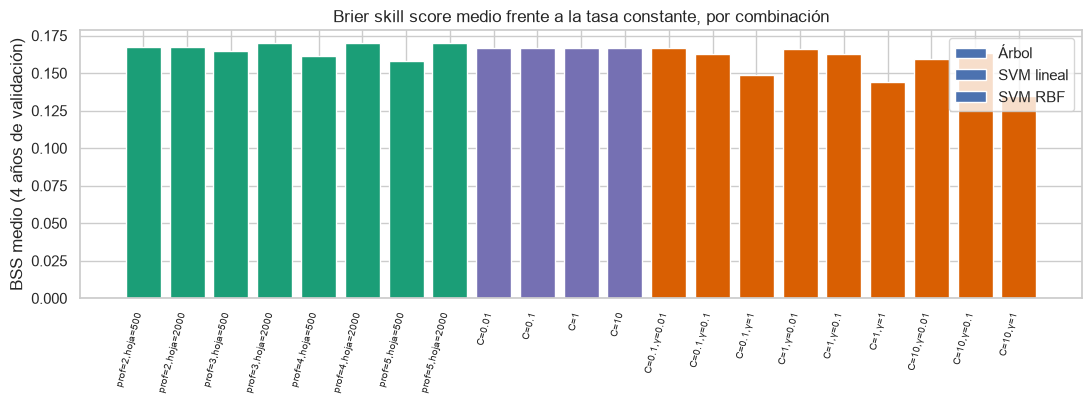

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.2))
col = {"arbol": "#1b9e77", "lineal": "#7570b3", "rbf": "#d95f02"}
etq = [c["id"].split("|")[1].replace("max_depth", "prof").replace("min_samples_leaf", "hoja").replace("gamma", "γ") for c in combos]
ax.bar(range(len(combos)), [c["bss_medio"] for c in combos], color=[col[c["algoritmo"]] for c in combos])
ax.set_xticks(range(len(combos))); ax.set_xticklabels(etq, rotation=75, ha="right", fontsize=7)
ax.set_ylabel("BSS medio (4 años de validación)"); ax.set_title("Brier skill score medio frente a la tasa constante, por combinación")
for alg in GRILLAS: ax.bar([], [], color=col[alg], label=NOMBRE[alg])
ax.legend(); plt.tight_layout(); plt.show()

**Lectura.** *Árbol:* el BSS medio va de 0,1579 (profundidad 5, hojas de 500) a 0,1699 (profundidades 3, 4 y 5 con hojas de 2 000). *SVM lineal (con pesos de clase):* las cuatro combinaciones dan 0,1670 de BSS medio (el AUC va de 0,7611 con C = 10 a 0,7894 con C = 1): con una ponderación que evita la solución trivial, `C` casi no cambia el resultado. *SVM RBF:* el mejor es C = 0,1 y gamma = 0,01 con 0,1668; al subir gamma o C el BSS baja hasta 0,1349 (C = 10, gamma = 1), señal de sobreajuste (frontera demasiado curva). Por año, los tres algoritmos se parecen: el BSS del árbol de profundidad 2 baja de 0,2073 (2015) a 0,1206 (2018), el año con más toques (tasa 0,285; 2015: 0,2235, 2016: 0,1564, 2017: 0,1823), porque el entrenamiento fue tranquilo (0,1435) y 2018 agitado; esa caída es del contexto y no de un algoritmo. El BSS frente a la línea base decil × k queda en +0,0005 (lineal), entre −0,0381 y +0,0002 (RBF) y entre −0,0106 y +0,0041 (árbol): ningún algoritmo se separa de la línea base en validación. Tiempos por ajuste: árbol menos de 1 s, SVM lineal de 13 a 21 s, SVM RBF de 28 a 35 s.

## 3. Las referencias, medidas como los modelos

La tasa constante y la línea base decil × k se evalúan con las mismas métricas y los mismos años. Importa por la **comparación justa**: el notebook 06 mostró que la distribución cambia entre conjuntos (un entrenamiento tranquilo y una prueba agitada), así que un BSS positivo frente a la tasa constante no prueba nada por sí solo; la comparación válida es contra la línea base **del mismo conjunto**.

In [7]:
# La línea base y la tasa constante se evalúan con las mismas métricas y los mismos años que los modelos.
filas = []
for nom, c in (("Tasa constante", "p_const"), ("Línea base decil × k", "p_base")):
    m = metricas(pv, c, p0)
    bss_a = {a: cm.brier_skill(g["y"], g[c], p0) for a, g in pv.assign(a=pv.anio.astype(str)).groupby("a")}
    filas.append({"referencia": nom, "AUC": m["auc"], "Brier": m["brier"], **{f"BSS {a}": bss_a[a] for a in anios}, "BSS medio": np.mean(list(bss_a.values()))})
lb_val = pd.DataFrame(filas); print(lb_val.to_string(index=False))
print(f"\nBrier de la tasa constante por año: " + ", ".join(f"{a}: {brier(g['y'], g['p_const']):.4f}" for a, g in pv.assign(a=pv.anio.astype(str)).groupby("a")))
res["linea_base"] = {"validacion": lb_val.to_dict("records"),
                     "tabla_decil_k": {str(k): ref_ent["tab"][k].round(6).tolist() for k in cm.K_GRID},
                     "cortes_decil_sigma": ref_ent["cortes"][1:-1].tolist()}

          referencia    AUC  Brier  BSS 2015  BSS 2016  BSS 2017  BSS 2018  BSS medio
      Tasa constante 0.5000 0.1683    0.0000    0.0000    0.0000    0.0000     0.0000
Línea base decil × k 0.7833 0.1402    0.2098    0.1828    0.1525    0.1210     0.1665

Brier de la tasa constante por año: 2015: 0.1800, 2016: 0.1321, 2017: 0.1505, 2018: 0.2238


**Lectura.** La línea base decil × k tiene en validación un AUC de 0,7833, un Brier de 0,1402 y un BSS medio de 0,1665 frente a la tasa constante (0,2098, 0,1828, 0,1525 y 0,1210 por año); la tasa constante, por construcción, tiene AUC 0,5 y Brier de 0,1683 (0,1800, 0,1321, 0,1505 y 0,2238 por año). La caída del BSS de 2015 a 2018 la comparten todas las referencias y los modelos: viene de comparar con una constante fijada en un entrenamiento tranquilo, no de un modelo en particular. Con este piso, los mejores modelos (árbol de profundidad 2, 0,1674; SVM lineal, 0,1670; SVM RBF, 0,1668) superan a la línea base por menos de 0,001: **el listón relevante no es la tasa constante sino la línea base**, que también conoce k, y es el que se usa en la decisión de §6. Los BSS de 0,167 frente a la constante miden sobre todo el efecto de **saber k** (la distancia del nivel), no un aporte de las variables de volatilidad.

## 4. Selección con la regla fijada (solo validación)

La regla es una sola, dentro de un algoritmo y entre algoritmos:

1. Calcular el BSS medio (media de los 4 años) de cada combinación frente a la tasa constante del entrenamiento.
2. Son **empatadas** las combinaciones a menos de `EMPATE_BSS = 0,005` del mejor.
3. Entre las empatadas gana la **más simple**, en este orden: árbol, SVM lineal, SVM RBF. Dentro de un algoritmo: menor profundidad o mayor `min_samples_leaf` (árbol), menor `C` (lineal), menor `C` y, a igual `C`, menor `gamma` (RBF).
4. Si dos quedan igual de simples, desempata el AUC (con estas grillas no ocurre, y se verifica).

La prueba **no se ha calculado** hasta esta celda; la selección queda escrita antes de abrirla.

In [8]:
def simplicidad(c):                            # menor = más simple (spec: árbol → lineal → RBF)
    a, hp = RANGO_SIMPLICIDAD[c["algoritmo"]], c["hiperparametros"]
    if c["algoritmo"] == "arbol": return (a, hp["max_depth"], -hp["min_samples_leaf"])
    if c["algoritmo"] == "lineal": return (a, hp["C"])
    return (a, hp["C"], hp["gamma"])           # RBF: menor C y, a igual C, menor gamma

def elegir(cs):
    """Una sola regla, dentro de un algoritmo y entre algoritmos: empate = a menos de EMPATE_BSS del mejor BSS medio;
    entre las empatadas gana la más simple; el AUC solo desempata si dos tienen la misma simplicidad."""
    mejor = max(c["bss_medio"] for c in cs)
    empatadas = [c for c in cs if mejor - c["bss_medio"] < cm.EMPATE_BSS]
    claves = [simplicidad(c) for c in empatadas]
    gana = min(empatadas, key=lambda c: (simplicidad(c), -c["auc"]))
    return gana, empatadas, mejor, len(set(claves)) < len(claves)

ganador, empatadas_alg, desempate = {}, {}, False
for alg in GRILLAS:
    g, emp, mejor, d = elegir([c for c in combos if c["algoritmo"] == alg])
    ganador[alg], empatadas_alg[alg], desempate = g, emp, desempate or d
    print(f"{NOMBRE[alg]}: mejor BSS medio = {mejor:.4f}; empatadas (a menos de {cm.EMPATE_BSS} del mejor): {len(emp)}")
    for c in sorted(emp, key=lambda c: -c["bss_medio"]):
        print(f"    {c['hiperparametros']}  BSS medio {c['bss_medio']:.4f}  (a {mejor - c['bss_medio']:.4f} del mejor)  AUC {c['auc']:.4f}")
    print(f"  → gana por simplicidad: {g['hiperparametros']} (BSS medio {g['bss_medio']:.4f})")
gg, emp_g, mejor_g, d = elegir(combos); desempate = desempate or d
print(f"\nGANADOR GLOBAL (21 combinaciones): mejor BSS medio {mejor_g:.4f}; empatadas: {len(emp_g)}")
for c in sorted(emp_g, key=lambda c: -c["bss_medio"]):
    print(f"    {NOMBRE[c['algoritmo']]} {c['hiperparametros']}  BSS medio {c['bss_medio']:.4f}  (a {mejor_g - c['bss_medio']:.4f} del mejor)")
print(f"  → {NOMBRE[gg['algoritmo']]} {gg['hiperparametros']} · desempate por AUC usado: {desempate}")
GANADOR_ALG = gg["algoritmo"]
res["seleccion"] = {"ganador_por_algoritmo": {a: {"hiperparametros": c["hiperparametros"], "bss_medio": c["bss_medio"], "auc": c["auc"]} for a, c in ganador.items()},
                    "ganador_global": {"algoritmo": GANADOR_ALG, "hiperparametros": gg["hiperparametros"], "bss_medio": gg["bss_medio"], "auc": gg["auc"]},
                    "empatadas": {**{a: [{"hiperparametros": c["hiperparametros"], "bss_medio": c["bss_medio"]} for c in e] for a, e in empatadas_alg.items()},
                                  "global": [{"algoritmo": c["algoritmo"], "hiperparametros": c["hiperparametros"], "bss_medio": c["bss_medio"]} for c in emp_g]},
                    "empate_bss": cm.EMPATE_BSS, "desempate_usado": bool(desempate)}

Árbol: mejor BSS medio = 0.1699; empatadas (a menos de 0.005 del mejor): 6
    {'max_depth': 4, 'min_samples_leaf': 2000}  BSS medio 0.1699  (a 0.0000 del mejor)  AUC 0.7875
    {'max_depth': 5, 'min_samples_leaf': 2000}  BSS medio 0.1699  (a 0.0000 del mejor)  AUC 0.7875
    {'max_depth': 3, 'min_samples_leaf': 2000}  BSS medio 0.1699  (a 0.0000 del mejor)  AUC 0.7860
    {'max_depth': 2, 'min_samples_leaf': 500}  BSS medio 0.1674  (a 0.0025 del mejor)  AUC 0.7715
    {'max_depth': 2, 'min_samples_leaf': 2000}  BSS medio 0.1674  (a 0.0025 del mejor)  AUC 0.7715
    {'max_depth': 3, 'min_samples_leaf': 500}  BSS medio 0.1650  (a 0.0049 del mejor)  AUC 0.7809
  → gana por simplicidad: {'max_depth': 2, 'min_samples_leaf': 2000} (BSS medio 0.1674)
SVM lineal: mejor BSS medio = 0.1670; empatadas (a menos de 0.005 del mejor): 4
    {'C': 0.01}  BSS medio 0.1670  (a 0.0000 del mejor)  AUC 0.7860
    {'C': 1}  BSS medio 0.1670  (a 0.0000 del mejor)  AUC 0.7894
    {'C': 0.1}  BSS medio 0.1670

**Lectura.** Con los SVM ponderados, **12 de las 21 combinaciones quedan empatadas** (a menos de 0,005 del mejor BSS medio, 0,1699): 6 árboles, las 4 del SVM lineal (0,1670) y 2 del RBF (0,1668 y 0,1664). Gana por simplicidad el **árbol de profundidad 2 con hojas de al menos 2 000 filas** (BSS medio 0,1674, a 0,0025 del mejor). Por algoritmo ganan el SVM lineal con C = 0,01 (el menor C entre cuatro empatadas) y el SVM RBF con C = 0,1 y gamma = 0,01. Los tres ganadores por algoritmo están a 0,0006 entre sí: **la validación no distingue entre algoritmos** y la regla de simplicidad decide. El desempate por AUC no se usó (`desempate_usado: false`). Con solo 4 años de validación y 12 combinaciones separadas por menos de 0,005, la elección es frágil por naturaleza.

**Diagnóstico de los SVM, antes y después de ponderar las clases (solo validación, no cambia la selección).** Para la configuración ganadora de cada SVM se entrena sin ponderar y con `class_weight="balanced"`, y se compara el AUC del puntaje crudo de la frontera con el de la probabilidad (Platt), la fracción de filas que la frontera pone del lado "toca" y el BSS medio.

In [9]:
# Diagnóstico (solo validación; no cambia la selección): antes (sin ponderar) y después (class_weight="balanced") para la configuración ganadora de cada SVM.
# Se compara el AUC del puntaje crudo de la frontera con el de la probabilidad (Platt) y la fracción de filas que la frontera pone del lado "toca".
filas = []
for alg in ("lineal", "rbf"):
    for nom, pesos in (("sin ponderar", None), ("balanced", "balanced")):
        mod = armar(alg, pesos=pesos, **ganador[alg]["hiperparametros"]).fit(Xtr, ytr)
        crudo = mod.decision_function(val[VARS]); prob = mod.predict_proba(val[VARS])[:, 1]
        filas.append({"modelo": NOMBRE[alg], "hiperparametros": ganador[alg]["hiperparametros"], "pesos": nom, "AUC puntaje crudo": auc(val["y"], crudo),
                      "AUC probabilidad (Platt)": auc(val["y"], prob), "filas con puntaje > 0": float((crudo > 0).mean()),
                      "BSS medio": float(np.mean([cm.brier_skill(g["y"], prob[(val["anio"] == a).to_numpy()], p0) for a, g in val.groupby("anio")]))})
diag = pd.DataFrame(filas); print(diag.to_string(index=False))
res["diagnostico_pesos_validacion"] = diag.to_dict("records")

    modelo           hiperparametros        pesos  AUC puntaje crudo  AUC probabilidad (Platt)  filas con puntaje > 0  BSS medio
SVM lineal               {'C': 0.01} sin ponderar             0.7577                    0.7577                 0.0000     0.0901
SVM lineal               {'C': 0.01}     balanced             0.7860                    0.7860                 0.3822     0.1670
   SVM RBF {'C': 0.1, 'gamma': 0.01} sin ponderar             0.5664                    0.5664                 0.0000     0.0279
   SVM RBF {'C': 0.1, 'gamma': 0.01}     balanced             0.7770                    0.7770                 0.3026     0.1668


**Lectura.** *Antes* (sin ponderar), la frontera deja el 0,0 % de las filas del lado "toca" y el BSS medio es 0,0901 (lineal, C = 0,01) y 0,0279 (RBF, C = 0,1 y gamma = 0,01). *Después* (`class_weight="balanced"`), el 38,2 % (lineal) y el 30,3 % (RBF) de las filas queda del lado "toca", el AUC sube de 0,7577 a 0,7860 (lineal) y de 0,5664 a 0,7770 (RBF), y el BSS medio a 0,1670 y 0,1668. En las cuatro filas el AUC del puntaje crudo coincide con el de la probabilidad: Platt no desordena a estos modelos. Sin ponderar, el SVM lineal con C = 10 daba un AUC de probabilidad de 0,2562 (ordenaba al revés); con ponderación esa combinación tiene 0,7611, así que era un artefacto de la solución trivial. La comparación entre algoritmos de §2 ya es justa: se usó la versión ponderada en todas las combinaciones de los dos SVM.

## 5. Reentrenar con 2009–2018 y medir en la prueba (una sola vez)

Los tres ganadores por algoritmo (con la configuración ya elegida) se reentrenan con las filas de 2009–2018, sin las últimas 60 sesiones antes de 2019 (brecha), y se evalúan en la prueba junto con las dos referencias (reajustadas con esas mismas filas). Los IC95 salen del **bootstrap por bloques de fechas** (bloques de 60 fechas con todas las acciones y k de cada fecha juntas), que conserva la dependencia entre fechas vecinas y entre acciones.

In [10]:
# --- A PARTIR DE AQUÍ se abre la prueba: la selección ya está fijada y guardada ---
prueba = tabla[tabla.conjunto_final == "prueba"]
fin = tabla[tabla.conjunto_final == "entrenamiento_final"]
assert fin["fecha"].max() < prueba["fecha"].min(), "el reentrenamiento no puede tocar la prueba"
fin_sub = cm.submuestra(fin)
ref_fin = ajustar_referencias(fin)                       # tasa constante, deciles y línea base reajustados con 2009–2018
p0_fin = ref_fin["p0"]
print(f"reentrenamiento: {fm(len(fin))} filas ({fin.fecha.min().date()} a {fin.fecha.max().date()}; la brecha de 60 sesiones antes de 2019 queda fuera) · submuestra: {fm(len(fin_sub))}")
print(f"prueba: {fm(len(prueba))} filas ({prueba.fecha.min().date()} a {prueba.fecha.max().date()}) · tasa constante reajustada p0 = {p0_fin:.4f}")
finales = {alg: armar(alg, **ganador[alg]["hiperparametros"]).fit(fin_sub[VARS], fin_sub["y"].astype(int)) for alg in GRILLAS}
pt = prueba[["fecha", "ticker", "k", "y", "sigma252", "anio"]].copy()
for alg in GRILLAS: pt[f"p_{alg}"] = finales[alg].predict_proba(prueba[VARS])[:, 1]
pt["p_const"] = p0_fin
pt["p_base"] = p_base(prueba, ref_fin)
print("modelos reentrenados y predicciones de la prueba calculadas una sola vez")

reentrenamiento: 185 136 filas (2010-01-04 a 2018-10-03; la brecha de 60 sesiones antes de 2019 queda fuera) · submuestra: 37 044
prueba: 159 432 filas (2019-01-02 a 2026-07-22) · tasa constante reajustada p0 = 0.1706


modelos reentrenados y predicciones de la prueba calculadas una sola vez


In [11]:
ENT = {"arbol": "p_arbol", "lineal": "p_lineal", "rbf": "p_rbf", "linea_base": "p_base", "tasa_constante": "p_const"}
def ic(df, f, bloque=cm.BLOQUE_FECHAS, **kw):
    return cm.ic_bootstrap_fechas(df, f, bloque=bloque, reps=cm.REPS_BOOT, semilla=cm.SEMILLA, **kw)
f_auc = lambda c: (lambda d: auc(d["y"].to_numpy(), d[c].to_numpy()))
f_brier = lambda c: (lambda d: brier(d["y"].to_numpy(), d[c].to_numpy()))
f_bss = lambda c: (lambda d: cm.brier_skill(d["y"].to_numpy(), d[c].to_numpy(), p0_fin))                 # frente a la tasa constante
f_bssb = lambda c: (lambda d: cm.brier_skill(d["y"].to_numpy(), d[c].to_numpy(), d["p_base"].to_numpy()))  # frente a la línea base decil × k
sl = lambda c, extra=(): pt[["fecha", "y", c, *extra]]                                                     # columnas mínimas para el bootstrap
prueba_res = {}
for nom, c in ENT.items():
    t0 = time.time()
    r = {"tasa_toque": float(pt["y"].mean())}
    if nom == "tasa_constante":                       # AUC = 0,5 por construcción (puntaje constante); BSS = 0 frente a sí misma
        r.update(auc=0.5, auc_ic95=[0.5, 0.5], brier=brier(pt["y"], pt[c]), bss=0.0, bss_ic95=[0.0, 0.0], bss_vs_linea_base=cm.brier_skill(pt["y"], pt[c], pt["p_base"].to_numpy()))
        e, lo, hi = ic(sl(c), f_brier(c)); r["brier_ic95"] = [lo, hi]
    else:
        e, lo, hi = ic(sl(c), f_auc(c)); r.update(auc=e, auc_ic95=[lo, hi])
        e, lo, hi = ic(sl(c), f_brier(c)); r.update(brier=e, brier_ic95=[lo, hi])
        e, lo, hi = ic(sl(c), f_bss(c)); r.update(bss=e, bss_ic95=[lo, hi])
        if nom != "linea_base":
            e, lo, hi = ic(sl(c, ("p_base",)), f_bssb(c)); r.update(bss_vs_linea_base=e, bss_vs_linea_base_ic95=[lo, hi])
    r["por_anio"] = {str(a): {**metricas(g, c, p0_fin), "n": len(g), "tasa_toque": float(g["y"].mean())} for a, g in pt.groupby("anio")}
    r["por_k"] = {str(k): {**metricas(g, c, p0_fin), "n": len(g), "tasa_toque": float(g["y"].mean())} for k, g in pt.groupby("k")}
    prueba_res[nom] = r
    print(f"{nom}: {time.time() - t0:.0f} s")
res["prueba"] = prueba_res

arbol: 17 s


lineal: 23 s


rbf: 28 s


linea_base: 17 s


tasa_constante: 2 s


In [12]:
nombres = {"arbol": "Árbol", "lineal": "SVM lineal", "rbf": "SVM RBF", "linea_base": "Línea base decil × k", "tasa_constante": "Tasa constante"}
f2 = lambda v: f"{v[0]:.4f} a {v[1]:.4f}"
tp = pd.DataFrame([{"modelo": nombres[n], "AUC": r["auc"], "IC95 AUC": f2(r["auc_ic95"]), "Brier": r["brier"], "IC95 Brier": f2(r["brier_ic95"]),
                    "BSS vs constante": r["bss"], "IC95 BSS": f2(r["bss_ic95"]),
                    "BSS vs base": r.get("bss_vs_linea_base", np.nan)} for n, r in prueba_res.items()])
print(f"Prueba 2019–{pt.fecha.max().year}: {fm(len(pt))} filas · tasa de toque {pt.y.mean():.4f} (entrenamiento final: {p0_fin:.4f})")
print(tp.to_string(index=False))
# AUC DENTRO de cada k: el AUC global (los 4 k apilados) mide sobre todo "saber k"; dentro de un k solo cuenta lo que aportan las variables.
dk = pd.DataFrame({nombres[n]: {k: v["auc"] for k, v in r["por_k"].items()} for n, r in prueba_res.items() if n != "tasa_constante"})
dk.loc["media de los 4 k"] = dk.mean()
print("\nAUC dentro de cada k (prueba):"); print(dk.round(4).to_string())
res["auc_dentro_de_k"] = dk.to_dict()
for nom in ("arbol", "lineal", "rbf", "linea_base"):
    print(f"\n{nombres[nom]} · por año de prueba y por k (AUC / BSS vs base)")
    t = pd.DataFrame({a: {"AUC": v["auc"], "BSS vs const": v["bss"], "BSS vs base": v["bss_vs_base"], "tasa": v["tasa_toque"]} for a, v in prueba_res[nom]["por_anio"].items()}).T
    print(t.round(4).T.to_string())
    print(pd.DataFrame({k: {"AUC": v["auc"], "BSS vs const": v["bss"], "BSS vs base": v["bss_vs_base"], "tasa": v["tasa_toque"]} for k, v in prueba_res[nom]["por_k"].items()}).round(4).to_string())

Prueba 2019–2026: 159 432 filas · tasa de toque 0.2010 (entrenamiento final: 0.1706)
              modelo    AUC        IC95 AUC  Brier      IC95 Brier  BSS vs constante        IC95 BSS  BSS vs base
               Árbol 0.7529 0.7134 a 0.7856 0.1375 0.1138 a 0.1680            0.1489 0.1129 a 0.1775      -0.0018
          SVM lineal 0.7783 0.7409 a 0.8112 0.1362 0.1135 a 0.1660            0.1564 0.1191 a 0.1884       0.0071
             SVM RBF 0.7681 0.7295 a 0.8005 0.1359 0.1128 a 0.1658            0.1586 0.1219 a 0.1902       0.0096
Línea base decil × k 0.7712 0.7353 a 0.8013 0.1372 0.1129 a 0.1679            0.1504 0.1139 a 0.1801          NaN
      Tasa constante 0.5000 0.5000 a 0.5000 0.1615 0.1348 a 0.1922            0.0000 0.0000 a 0.0000      -0.1771

AUC dentro de cada k (prueba):
                  Árbol  SVM lineal  SVM RBF  Línea base decil × k
0.5              0.5026      0.5575   0.5681                0.4877
1.0              0.5000      0.5874   0.5301                0.588

**Lectura.** En la prueba (2019 a julio de 2026, 159 432 filas, tasa de toque 0,2010 frente a 0,1706 del entrenamiento reajustado) el **árbol** tiene AUC 0,7529 (IC95 0,7134 a 0,7856), Brier 0,1375 y BSS 0,1489 frente a la tasa constante; el **SVM lineal** AUC 0,7783 (0,7409 a 0,8112), Brier 0,1362 y BSS 0,1564; el **SVM RBF** AUC 0,7681 (0,7295 a 0,8005), Brier 0,1359 y BSS 0,1586; la **línea base decil × k** AUC 0,7712 (0,7353 a 0,8013), Brier 0,1372 y BSS 0,1504. Frente a la línea base, el BSS es −0,0018 (árbol), +0,0071 (lineal) y +0,0096 (RBF), y los IC95 de los tres cruzan 0 (el del árbol, −0,0088 a +0,0032). Por año, el árbol frente a la línea base va de −0,0209 (2020) a +0,0085 (2025 y 2026); el SVM lineal, de −0,0334 (2021) a +0,0372 (2025). **Las cifras globales miden sobre todo saber k.** El AUC **dentro de cada k** es mucho menor: el árbol 0,5026, 0,5000, 0,5000 y 0,5000 (media 0,5006) con k = 0,5, 1, 1,5 y 2; el SVM lineal 0,5575, 0,5874, 0,6166 y 0,6161 (media 0,5944); el SVM RBF 0,5681, 0,5301, 0,4722 y 0,4750 (media 0,5113); y la línea base 0,4877, 0,5884, 0,6198 y 0,5776 (media 0,5684). Es decir, el AUC de 0,75 a 0,78 viene casi todo de que la tasa de toque cambia con k (0,4578, 0,2057, 0,0926 y 0,0478 en la prueba); lo que las variables de volatilidad agregan dentro de un k es de 0,50 a 0,62 de AUC. La comparación que importa es la que ya conoce k: contra la línea base decil × k.

## 6. ¿El ganador aporta algo más que la volatilidad? (plantilla de inferencia del profesor)

**Qué cambia respecto del umbral original.** El umbral de 0,03 nació para k = 1 y sin k como variable. Ahora el AUC se calcula sobre los 4 k apilados y se compara con una línea base decil × k, así que ΔAUC mide el aporte del modelo **sobre la volatilidad y sobre k**, no el de la entrega 1.

**Paso 0 · umbral práctico.** ΔAUC = **0,03** (fila "SVM: umbral" de `04_enfoque_analitico.md` §4.5, fijada antes de la entrega 2). Es el aumento mínimo de AUC que justificaría presentar la lectura técnica como una señal accionable y no como un dato de contexto: una mejora de 2 a 4 puntos de AUC sobre una buena línea base ya es valiosa, y por debajo de 3 puntos el ruido de una sola semana de volatilidad la borra.

**H0 y H1, α.** H0: ΔAUC = AUC(ganador) − AUC(línea base decil × k) = 0. H1: ΔAUC > 0. α = 0,05, IC95 bilateral por bootstrap de bloques de fechas.

In [13]:
def decision_negocio(lo, hi, umbral, rechaza_h0):          # copia de nb04 §5: las tres etiquetas del enfoque analítico
    if lo > umbral: return "accionable"
    if rechaza_h0 and lo <= umbral <= hi: return "efecto real, pero de magnitud incierta"
    return "no accionable"

print(f"Paso 0 — umbral práctico: ΔAUC = {UMBRAL_DAUC}  (fijado antes de la entrega 2)")
print(f"H0: ΔAUC = AUC({NOMBRE[GANADOR_ALG]}) − AUC(línea base decil × k) = 0   |   H1: ΔAUC > 0   |   α = {ALFA}, IC95 bilateral")
GAN = f"p_{GANADOR_ALG}"
print(f"Ganador global: {NOMBRE[GANADOR_ALG]} {gg['hiperparametros']}")

Paso 0 — umbral práctico: ΔAUC = 0.03  (fijado antes de la entrega 2)
H0: ΔAUC = AUC(Árbol) − AUC(línea base decil × k) = 0   |   H1: ΔAUC > 0   |   α = 0.05, IC95 bilateral
Ganador global: Árbol {'max_depth': 2, 'min_samples_leaf': 2000}


**Matriz de supuestos.** Con observaciones dependientes (las etiquetas de 60 sesiones se solapan, las 21 acciones se mueven juntas y los 4 k de una misma fecha y acción casi coinciden) la decisión sale del **IC por bootstrap por bloques de fechas**, no del p-value clásico.

| # | Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué se hace si falla |
|---|---|---|---|---|---|
| i | Independencia entre filas | El solapamiento de las etiquetas de 60 sesiones infla la muestra aparente y estrecha el IC clásico | Autocorrelación de `y` a rezagos 1 y 60 por (acción, k), mediana de las 84 series | 0,883 (rezago 1) y −0,037 (rezago 60): filas vecinas casi copias; a 60 sesiones, casi independientes | Bootstrap por bloques de fechas (no se usa el IC clásico) |
| i-bis | Independencia entre k de una misma fecha | Los 4 k de una (fecha, acción) comparten el mismo futuro | Correlación de `y` entre pares de k en la misma (fecha, acción) | 0,244 a 0,702 (media 0,486) | El bloque lleva todas las acciones y los 4 k de cada fecha juntos |
| ii | Bloque suficiente | Un bloque corto deja dependencia residual y estrecha el IC | IC de ΔAUC con bloques de 20, 60 y 120 fechas | anchos 0,0102, 0,0141 y 0,0163; mismo signo y posición | Se adopta el bloque más ancho si el IC cambia |
| iii | Estabilidad de la diferencia | Un promedio puede esconder años o regímenes opuestos | ΔAUC con IC por año de prueba y por los 4 subperíodos (sin decisión) | de +0,0018 (2019) a −0,0523 (2020); ningún año ni subperíodo con IC por encima de 0 | Se reporta la inestabilidad como limitación |
| iv | Tamaño efectivo suficiente | Pocos bloques independientes = IC poco fiable | Fechas de prueba, bloques por réplica y réplicas | 1 898 fechas, 32 bloques de 60 fechas, 1 000 réplicas | Más réplicas o bloque menor |
| v | La referencia no mira la prueba | Una línea base que viera la prueba exageraría o reduciría ΔAUC | Fechas de las filas con que se ajustó frente a la primera fecha de prueba | ajuste hasta el 2018-10-03; prueba desde el 2019-01-02 | Reajustar con filas anteriores |

In [14]:
# Supuestos de la prueba. Cada fila: verificación ejecutada y cifra.
# (i) Independencia entre filas: las etiquetas de 60 sesiones se solapan → autocorrelación de y por (ticker, k).
srt = pt.sort_values("fecha")
ac = {rz: srt.groupby(["ticker", "k"])["y"].apply(lambda s: s.autocorr(rz)) for rz in (1, 60)}
for rz, s in ac.items():
    print(f"(i) autocorrelación de y a rezago {rz}: mediana de las {len(s)} series (ticker, k) = {s.median():.3f} (mín {s.min():.3f}, máx {s.max():.3f})")
# (i-bis) dependencia entre k de una misma (fecha, ticker)
pk = pt.pivot_table(index=["fecha", "ticker"], columns="k", values="y")
cc = pk.corr(); off = cc.to_numpy()[np.triu_indices(len(cc), 1)]
print(f"(i-bis) correlación de y entre pares de k en la misma (fecha, ticker): mín {off.min():.3f}, media {off.mean():.3f}, máx {off.max():.3f}")
print(cc.round(3).to_string())
# (iv) tamaño efectivo
nf = pt["fecha"].nunique()
print(f"(iv) fechas de prueba: {fm(nf)} → {int(np.ceil(nf / cm.BLOQUE_FECHAS))} bloques de {cm.BLOQUE_FECHAS} fechas por réplica, {fm(cm.REPS_BOOT)} réplicas; cada fecha trae {pt.groupby('fecha').size().median():.0f} filas (21 acciones × 4 k)")
# (v) la referencia usa solo el entrenamiento
print(f"(v) la línea base se ajustó con filas de {fin.fecha.min().date()} a {fin.fecha.max().date()} y la prueba empieza el {prueba.fecha.min().date()}: sin look-ahead")
res["supuestos"] = {"autocorr_rezago1_mediana": float(ac[1].median()), "autocorr_rezago60_mediana": float(ac[60].median()),
                    "corr_entre_k": {"min": float(off.min()), "media": float(off.mean()), "max": float(off.max())},
                    "fechas_prueba": int(nf), "bloques_por_replica": int(np.ceil(nf / cm.BLOQUE_FECHAS))}

(i) autocorrelación de y a rezago 1: mediana de las 84 series (ticker, k) = 0.883 (mín 0.332, máx 0.982)
(i) autocorrelación de y a rezago 60: mediana de las 84 series (ticker, k) = -0.037 (mín -0.202, máx 0.208)
(i-bis) correlación de y entre pares de k en la misma (fecha, ticker): mín 0.244, media 0.486, máx 0.702
k       0.5000  1.0000  1.5000  2.0000
k                                     
0.5000  1.0000  0.5540  0.3480  0.2440
1.0000  0.5540  1.0000  0.6280  0.4400
1.5000  0.3480  0.6280  1.0000  0.7020
2.0000  0.2440  0.4400  0.7020  1.0000
(iv) fechas de prueba: 1 898 → 32 bloques de 60 fechas por réplica, 1 000 réplicas; cada fecha trae 84 filas (21 acciones × 4 k)
(v) la línea base se ajustó con filas de 2010-01-04 a 2018-10-03 y la prueba empieza el 2019-01-02: sin look-ahead


**Lectura de la matriz.** (i) *Independencia:* la autocorrelación de `y` a un rezago de 1 sesión es 0,883 por mediana de las 84 series (acción, k) (mín 0,332, máx 0,982) y a 60 sesiones −0,037 (−0,202 a 0,208): las filas vecinas son casi copias, y a un horizonte de 60 sesiones la dependencia casi desaparece; por eso el bloque de 60 fechas es el adecuado y el IC clásico no se usa. (i-bis) La correlación de `y` entre pares de k de una misma (fecha, acción) va de 0,244 a 0,702 (media 0,486): por eso cada bloque lleva las 21 acciones y los 4 k juntos. (ii) *Bloque:* ΔAUC = −0,0183 con IC95 de [−0,0237, −0,0134] (bloque de 20), [−0,0261, −0,0120] (60) y [−0,0274, −0,0112] (120): el IC se ensancha de 0,0102 a 0,0163 al alargar el bloque, pero la posición y el signo no cambian; se mantiene el de 60 y la decisión es la misma con el de 120. (iii) *Estabilidad:* la diferencia por año (IC por bloques de 20 fechas, para que quepan unos 12 bloques por año) va de +0,0018 (2019) a −0,0523 (2020); el IC queda por debajo de 0 en 2022, 2023, 2025 y 2026, cruza 0 en 2019, 2021 y 2024, y en 2020 su límite superior es 0,0000 y se revisó (ver abajo). Por subperíodo: 2010–2012 no tiene filas de prueba (es anterior a 2019; no aplica); 2013–2019 (en la prueba solo 2019) +0,0018 [−0,0053, +0,0093]; 2020–2021 −0,0315 [−0,0446, −0,0054]; 2022+ −0,0161 [−0,0201, −0,0107]. Ningún año ni subperíodo tiene el IC por encima de 0: la ventaja del árbol sobre la línea base no aparece en ninguno. (iv) *Tamaño efectivo:* 1 898 fechas de prueba, 32 bloques de 60 fechas por réplica y 1 000 réplicas (84 filas por fecha). (v) *Sin look-ahead:* la línea base se ajustó con filas del 4 de enero de 2010 al 3 de octubre de 2018 y la prueba empieza el 2 de enero de 2019. **Revisión del IC de 2020.** El 3,9 % de las 1 000 réplicas tiene ΔAUC exactamente 0 y en todas ellas no hay ningún toque con k ≥ 1,5 (las réplicas que dejan fuera los meses de la caída de 2020): sin esos toques el árbol y la línea base ordenan igual, porque ambos solo distinguen k. Es una masa real de réplicas y no un error de cálculo; por eso el percentil 97,5 es exactamente 0.

**Estimación con IC antes del p-value.** Primero el tamaño de la diferencia con su intervalo (qué tan grande y qué tan incierta es), después el p bootstrap unilateral `(1 + #réplicas ≤ 0) / (1 + réplicas)`.

In [15]:
# Estimación con IC antes del p-value: ΔAUC por bloques de fechas (con todas las acciones y k de cada fecha juntas).
d_auc = lambda c, ref: (lambda d: auc(d["y"].to_numpy(), d[c].to_numpy()) - auc(d["y"].to_numpy(), d[ref].to_numpy()))
cols_dec = ["fecha", "y", GAN, "p_base", "p_const"]
delta, lo, hi, reps_d = ic(pt[cols_dec], d_auc(GAN, "p_base"), devolver_reps=True)
p_boot = float((1 + np.sum(reps_d <= 0)) / (1 + len(reps_d)))
print(f"AUC ganador = {prueba_res[GANADOR_ALG]['auc']:.4f} · AUC línea base decil × k = {prueba_res['linea_base']['auc']:.4f}")
print(f"ΔAUC = {delta:+.4f}   IC95 por bloques de fechas = [{lo:+.4f}, {hi:+.4f}]")
print(f"p bootstrap unilateral (1 + #réplicas ≤ 0)/(1 + {len(reps_d)}) = {p_boot:.4f}")
# Sensibilidad del bloque (supuesto ii) y estabilidad (iii)
sens = {}
for b in (20, 60, 120):
    e, l, h = ic(pt[cols_dec], d_auc(GAN, "p_base"), bloque=b); sens[b] = (e, l, h)
    print(f"bloque de {b:>3} fechas: ΔAUC {e:+.4f}  IC95 [{l:+.4f}, {h:+.4f}]  (ancho {h - l:.4f})")
print("\n(iii) ΔAUC por año de prueba (con IC por bloques de fechas; sin decisión):")
por_anio_d = {}
for a, g in pt.groupby("anio"):
    e, l, h = ic(g[cols_dec], d_auc(GAN, "p_base"), bloque=min(BLOQUE_SUB, g["fecha"].nunique())); por_anio_d[str(a)] = {"delta_auc": e, "ic95": [l, h], "n": len(g)}
    print(f"  {a}: ΔAUC {e:+.4f}  IC95 [{l:+.4f}, {h:+.4f}]  (n = {fm(len(g))})")
print("\n(iii) ΔAUC por subperíodo (sin decisión):")
por_sub_d = {}
for nom, (a0, a1) in SUBPERIODOS.items():
    g = pt[(pt.anio >= a0) & (pt.anio <= a1)]
    if len(g) == 0:
        por_sub_d[nom] = {"sin_filas_de_prueba": True}; print(f"  {nom}: sin filas de prueba (el subperíodo es anterior a 2019; no aplica)"); continue
    if g.anio.min() > a0: nom = nom + f" (en la prueba: años {g.anio.min()}–{g.anio.max()})"      # rótulo con los años que sí tienen prueba
    e, l, h = ic(g[cols_dec], d_auc(GAN, "p_base"), bloque=min(BLOQUE_SUB, g["fecha"].nunique())); por_sub_d[nom] = {"delta_auc": e, "ic95": [l, h], "n": len(g)}
    print(f"  {nom}: ΔAUC {e:+.4f}  IC95 [{l:+.4f}, {h:+.4f}]  (n = {fm(len(g))}, años {g.anio.min()}–{g.anio.max()})")

# IC de 2020 con límite superior exactamente 0: se revisan las réplicas (no es un bloque degenerado ni redondeo).
registro = []
def f_2020(d):
    v = d_auc(GAN, "p_base")(d); registro.append((v, int(d.loc[d["k"] >= 1.5, "y"].sum()))); return v
g20 = pt.loc[pt.anio == 2020, cols_dec + ["k"]]
e20, l20, h20 = ic(g20, f_2020, bloque=BLOQUE_SUB)
reg = np.array(registro[:-1]); cero = reg[:, 0] == 0                   # la última llamada es la estimación con todos los datos
print(f"2020: {cero.mean() * 100:.1f} % de las {len(reg)} réplicas tienen ΔAUC exactamente 0; de ellas, {(reg[cero, 1] == 0).mean() * 100:.0f} % no tienen ningún toque con k ≥ 1,5 "
      f"(sin esos toques el árbol y la línea base ordenan igual: ambos solo distinguen k). Por eso el percentil 97,5 es 0: es una masa real de réplicas, no un error.")
res_2020 = {"pct_replicas_cero": float(cero.mean() * 100), "pct_de_ellas_sin_toques_k_alto": float((reg[cero, 1] == 0).mean() * 100)}

AUC ganador = 0.7529 · AUC línea base decil × k = 0.7712
ΔAUC = -0.0183   IC95 por bloques de fechas = [-0.0261, -0.0120]
p bootstrap unilateral (1 + #réplicas ≤ 0)/(1 + 1000) = 1.0000


bloque de  20 fechas: ΔAUC -0.0183  IC95 [-0.0237, -0.0134]  (ancho 0.0102)


bloque de  60 fechas: ΔAUC -0.0183  IC95 [-0.0261, -0.0120]  (ancho 0.0141)


bloque de 120 fechas: ΔAUC -0.0183  IC95 [-0.0274, -0.0112]  (ancho 0.0163)

(iii) ΔAUC por año de prueba (con IC por bloques de fechas; sin decisión):


  2019: ΔAUC +0.0018  IC95 [-0.0053, +0.0093]  (n = 21 168)


  2020: ΔAUC -0.0523  IC95 [-0.0676, +0.0000]  (n = 21 252)


... (6 outputs left out)

  2013–2019 (en la prueba: años 2019–2019): ΔAUC +0.0018  IC95 [-0.0053, +0.0093]  (n = 21 168, años 2019–2019)


  2020–2021: ΔAUC -0.0315  IC95 [-0.0446, -0.0054]  (n = 42 420, años 2020–2021)


  2022+: ΔAUC -0.0161  IC95 [-0.0201, -0.0107]  (n = 95 844, años 2022–2026)


2020: 3.9 % de las 1000 réplicas tienen ΔAUC exactamente 0; de ellas, 100 % no tienen ningún toque con k ≥ 1,5 (sin esos toques el árbol y la línea base ordenan igual: ambos solo distinguen k). Por eso el percentil 97,5 es 0: es una masa real de réplicas, no un error.


**Lectura.** El AUC del árbol (0,7529) es menor que el de la línea base decil × k (0,7712): ΔAUC = −0,0183, con IC95 por bloques de fechas de [−0,0261, −0,0120]. El p bootstrap unilateral es 1,0000: ninguna de las 1 000 réplicas dio una diferencia positiva. No es una prueba a favor del árbol; el intervalo completo está del lado negativo.

**Efecto con IC.** ΔAUC en puntos de AUC y la diferencia de error cuadrático (ΔBrier y BSS frente a la línea base). Se repite contra la tasa constante como información adicional, **sin** decisión de negocio.

In [16]:
# Efecto con IC: ΔBrier (positivo = el ganador se equivoca menos) y BSS frente a la línea base.
d_brier = lambda c, ref: (lambda d: brier(d["y"].to_numpy(), d[ref].to_numpy()) - brier(d["y"].to_numpy(), d[c].to_numpy()))
db, dlo, dhi = ic(pt[cols_dec], d_brier(GAN, "p_base"))
bb, blo, bhi = ic(pt[["fecha", "y", GAN, "p_base"]], f_bssb(GAN))
print(f"ΔAUC = {delta * 100:+.2f} puntos de AUC  IC95 [{lo * 100:+.2f}, {hi * 100:+.2f}]")
print(f"ΔBrier (línea base − ganador) = {db:+.5f}  IC95 [{dlo:+.5f}, {dhi:+.5f}]")
print(f"BSS frente a la línea base decil × k = {bb:+.4f}  IC95 [{blo:+.4f}, {bhi:+.4f}]")
# Mismo bloque contra la tasa constante (información adicional, sin decisión de negocio): su AUC es 0,5
dc, clo, chi_, reps_c = ic(pt[cols_dec], d_auc(GAN, "p_const"), devolver_reps=True)
p_boot_c = float((1 + np.sum(reps_c <= 0)) / (1 + len(reps_c)))
dbc, dbclo, dbchi = ic(pt[cols_dec], d_brier(GAN, "p_const"))
bc, bclo, bchi = prueba_res[GANADOR_ALG]["bss"], *prueba_res[GANADOR_ALG]["bss_ic95"]
# Información (sin decisión: la selección ya eligió el árbol): ΔAUC de los otros dos algoritmos frente a la línea base decil × k
otros = {}
for alg in ("lineal", "rbf"):
    e_, l_, h_ = ic(pt[["fecha", "y", f"p_{alg}", "p_base"]], d_auc(f"p_{alg}", "p_base")); otros[alg] = {"delta_auc": e_, "ic": [l_, h_]}
    print(f"Informativo · {NOMBRE[alg]} frente a la línea base: ΔAUC = {e_:+.4f}  IC95 [{l_:+.4f}, {h_:+.4f}]")
print(f"\nContra la tasa constante (información adicional): ΔAUC = {dc:+.4f} IC95 [{clo:+.4f}, {chi_:+.4f}] · p bootstrap {p_boot_c:.4f}")
print(f"   ΔBrier = {dbc:+.5f} IC95 [{dbclo:+.5f}, {dbchi:+.5f}] · BSS = {bc:+.4f} IC95 [{bclo:+.4f}, {bchi:+.4f}]")

ΔAUC = -1.83 puntos de AUC  IC95 [-2.61, -1.20]
ΔBrier (línea base − ganador) = -0.00024  IC95 [-0.00109, +0.00049]
BSS frente a la línea base decil × k = -0.0018  IC95 [-0.0088, +0.0032]


Informativo · SVM lineal frente a la línea base: ΔAUC = +0.0071  IC95 [-0.0021, +0.0155]


Informativo · SVM RBF frente a la línea base: ΔAUC = -0.0030  IC95 [-0.0102, +0.0036]

Contra la tasa constante (información adicional): ΔAUC = +0.2529 IC95 [+0.2134, +0.2856] · p bootstrap 0.0010
   ΔBrier = +0.02405 IC95 [+0.01858, +0.02936] · BSS = +0.1489 IC95 [+0.1129, +0.1775]


**Lectura.** En puntos de AUC, el árbol queda 1,83 puntos por debajo de la línea base (IC95 de −2,61 a −1,20). En error de probabilidad la diferencia es mínima y no distinguible de 0: ΔBrier = −0,00024 (−0,00109 a +0,00049) y BSS frente a la línea base de −0,0018 (−0,0088 a +0,0032). Las dos métricas no dicen lo mismo y eso es informativo: el AUC mira el **orden** (dentro de un mismo k la línea base tiene 10 valores distintos de probabilidad y el árbol uno o dos, así que ordena mejor dentro de un k), y el Brier mira cuánto se equivoca el **número** (casi igual). Como información (la selección ya eligió el árbol, así que no hay decisión), el ΔAUC de los otros dos algoritmos frente a la línea base es +0,0071 (IC95 −0,0021 a +0,0155) para el SVM lineal y −0,0030 (−0,0102 a +0,0036) para el SVM RBF: ninguno se distingue de 0. Contra la tasa constante, como información adicional: ΔAUC = +0,2529 (IC95 +0,2134 a +0,2856, p bootstrap 0,0010), ΔBrier = +0,02405 (+0,01858 a +0,02936) y BSS = +0,1489 (+0,1129 a +0,1775); esa ventaja se asocia sobre todo con que el árbol conoce k y la constante no.

**Dos decisiones.** La **estadística** compara el IC con el nulo (0): "se rechaza H0" si el IC95 excluye 0, "no se rechaza H0" si no. La de **negocio** compara el **límite inferior** del IC con el umbral 0,03 fijado antes: "accionable" si lo supera, "efecto real, pero de magnitud incierta" si se rechaza H0 y el IC cruza 0,03, y "no accionable" en los demás casos.

In [17]:
rechaza = lo > 0                                            # el IC95 bilateral excluye 0 por arriba
dec_est = "se rechaza H0" if rechaza else "no se rechaza H0"
dec_neg = decision_negocio(lo, hi, UMBRAL_DAUC, rechaza)
dec_est_c = "se rechaza H0" if clo > 0 else "no se rechaza H0"
print(f"Decisión estadística (IC frente al nulo 0):             {dec_est}")
print(f"Decisión de negocio (límite inferior frente a {UMBRAL_DAUC}):   {dec_neg}")
print(f"Contra la tasa constante (solo información):            {dec_est_c}")
if dec_neg != "accionable":
    print("→ La lectura técnica del producto se presenta como INFORMATIVA (no como señal accionable).")
res["decision_modelo"] = {"modelo": {"algoritmo": GANADOR_ALG, "hiperparametros": gg["hiperparametros"]}, "referencia": "linea_base_decil_k",
                          "umbral": UMBRAL_DAUC, "delta_auc": delta, "ic": [lo, hi], "p_boot": p_boot,
                          "decision_estadistica": dec_est, "decision_negocio": dec_neg,
                          "efecto": {"delta_brier": db, "delta_brier_ic": [dlo, dhi], "bss_vs_linea_base": bb, "bss_vs_linea_base_ic": [blo, bhi]},
                          "sensibilidad_bloque": {str(b): {"delta_auc": v[0], "ic": [v[1], v[2]]} for b, v in sens.items()},
                          "por_anio": por_anio_d, "por_subperiodo": por_sub_d,
                          "otros_algoritmos_informativo": otros, "ic_2020_revision": res_2020, "contra_tasa_constante": {"delta_auc": dc, "ic": [clo, chi_], "p_boot": p_boot_c, "decision_estadistica": dec_est_c,
                                                    "delta_brier": dbc, "delta_brier_ic": [dbclo, dbchi], "bss": bc, "bss_ic": [bclo, bchi]}}

Decisión estadística (IC frente al nulo 0):             no se rechaza H0
Decisión de negocio (límite inferior frente a 0.03):   no accionable
Contra la tasa constante (solo información):            se rechaza H0
→ La lectura técnica del producto se presenta como INFORMATIVA (no como señal accionable).


**Lectura.** *Decisión estadística:* **no se rechaza H0** (el IC95 de ΔAUC, [−0,0261, −0,0120], no queda por encima de 0; de hecho queda entero por debajo, lo que se asocia con que el árbol ordena peor que la línea base, no con que ordene mejor). *Decisión de negocio:* **no accionable** (el límite inferior, −0,0261, no supera el umbral de 0,03 fijado antes). Frente a la tasa constante, solo como información, **se rechaza H0**, pero esa comparación no es la que decide. Por tanto la lectura técnica del producto es **informativa**. Ningún algoritmo supera la línea base de forma distinguible: los IC de ΔAUC de los dos SVM cruzan 0, así que cambiar el ganador por uno de ellos no cambiaría la decisión de negocio.

**Implicación para el inversor y limitaciones.** *Implicación (en lenguaje de asociación):* la probabilidad técnica que ve el inversor se asocia con la tasa histórica de toque según qué tan lejos fija su nivel (k) y, a lo sumo, con el nivel de volatilidad de la acción; el modelo no agrega información sobre el día que no tenga ya la línea base, así que sirve como contexto ("en datos pasados, un nivel así de lejos se tocó cerca de X % de las veces") y no como una señal de cuándo actuar. *Limitaciones:* (1) la **fuga declarada**: N = 60 se eligió con datos hasta 2018 y la prueba de 2019 en adelante ya se miró en la entrega 1 para descartar los 7 indicadores, así que estos resultados se leen como confirmación y no como descubrimiento; (2) la distribución **no se conserva** entre conjuntos (5 de los 9 criterios del notebook 06 fallan: entrenamiento tranquilo, prueba agitada), por lo que el BSS se lee por año y contra la línea base del mismo conjunto; (3) k, N y las variables se fijaron antes de este análisis, y se probaron 21 combinaciones solo con 4 años de validación; (4) el árbol ganador solo emite 4 probabilidades distintas, y los SVM se entrenaron con pesos de clase y probabilidad de Platt; (5) un resultado negativo aquí no prueba que no exista señal técnica, solo que estas tres técnicas con estas cuatro variables no la encuentran sobre la volatilidad y k.

## 7. Calibración

Un diagrama de calibración agrupa las filas de la prueba en 10 tramos por **cuantiles** de la probabilidad predicha y compara, en cada tramo, la probabilidad media predicha con la frecuencia observada de toque; los tramos con menos de 200 filas se fusionan. Si el modelo está calibrado los puntos caen sobre la diagonal. Para el ganador se agrega el IC95 de la frecuencia observada de cada tramo (bootstrap por bloques de fechas): es el intervalo que la API mostrará como incertidumbre de la lectura técnica. "Error medio de calibración" es el promedio, ponderado por filas, de la distancia entre lo predicho y lo observado por tramo.

In [18]:
def tramos(p, y, n_grupos=10, min_n=200):
    """10 grupos por cuantiles de la probabilidad predicha; los grupos con menos de `min_n` filas se fusionan con su vecino."""
    bordes = np.unique(np.quantile(p, np.linspace(0, 1, n_grupos + 1)))
    if len(bordes) < 2: bordes = np.array([0.0, 1.0])          # predicción constante: un solo tramo
    bordes[0], bordes[-1] = 0.0, 1.0
    while True:
        g = pd.cut(p, bordes, include_lowest=True, labels=False).astype(int)
        n = np.bincount(g, minlength=len(bordes) - 1)
        if n.min() >= min_n or len(n) == 1: break
        i = int(np.argmin(n))
        if i == 0: j = 1
        elif i == len(n) - 1: j = len(n) - 1
        else: j = i if n[i - 1] <= n[i + 1] else i + 1                     # se elimina el borde interior hacia el vecino más chico
        bordes = np.delete(bordes, j)
    g = pd.cut(p, bordes, include_lowest=True, labels=False).astype(int)
    out = pd.DataFrame({"g": g, "p": p, "y": y}).groupby("g").agg(p_media=("p", "mean"), tasa_obs=("y", "mean"), n=("y", "size")).reset_index(drop=True)
    out.insert(0, "tramo_lo", bordes[:-1]); out.insert(1, "tramo_hi", bordes[1:])
    return out, g

def ece(t): return float((t["n"] * (t["tasa_obs"] - t["p_media"]).abs()).sum() / t["n"].sum())   # error medio de calibración, ponderado

cal, cal_g = {}, {}
for nom in ("arbol", "lineal", "rbf", "linea_base"):
    cal[nom], cal_g[nom] = tramos(pt[ENT[nom]].to_numpy(), pt["y"].to_numpy())
    print(f"{nombres[nom]}: {len(cal[nom])} tramos · error medio de calibración (ponderado) = {ece(cal[nom]) * 100:.2f} pp")
print(f"\nTramos del ganador ({NOMBRE[GANADOR_ALG]}):"); print(cal[GANADOR_ALG].to_string(index=False))
# IC95 de la tasa observada por tramo del ganador (bootstrap por bloques de fechas)
gcal = pt[["fecha", "y"]].assign(tramo=cal_g[GANADOR_ALG])
ics = [ic(gcal, (lambda j: (lambda d: float(d.loc[d["tramo"] == j, "y"].mean()) if (d["tramo"] == j).any() else np.nan))(j)) for j in range(len(cal[GANADOR_ALG]))]
cal[GANADOR_ALG]["ic_lo"] = [x[1] for x in ics]; cal[GANADOR_ALG]["ic_hi"] = [x[2] for x in ics]
print("\ncon IC95 de la tasa observada:"); print(cal[GANADOR_ALG][["tramo_lo", "tramo_hi", "p_media", "tasa_obs", "ic_lo", "ic_hi", "n"]].to_string(index=False))
# Por k (ganador)
cal_k = {str(k): tramos(g[GAN].to_numpy(), g["y"].to_numpy())[0] for k, g in pt.groupby("k")}
for k, t in cal_k.items(): print(f"k = {k}: {len(t)} tramos · error medio de calibración = {ece(t) * 100:.2f} pp")
res["calibracion"] = {nom: {"ece_pp": ece(t) * 100, "tramos": t.to_dict("records")} for nom, t in cal.items()}
res["calibracion"]["ganador_por_k"] = {k: {"ece_pp": ece(t) * 100, "tramos": t.to_dict("records")} for k, t in cal_k.items()}

Árbol: 4 tramos · error medio de calibración (ponderado) = 3.85 pp
SVM lineal: 10 tramos · error medio de calibración (ponderado) = 3.90 pp
SVM RBF: 10 tramos · error medio de calibración (ponderado) = 3.31 pp
Línea base decil × k: 10 tramos · error medio de calibración (ponderado) = 4.90 pp

Tramos del ganador (Árbol):
 tramo_lo  tramo_hi  p_media  tasa_obs     n
   0.0000    0.1098   0.0418    0.0702 79716
   0.1098    0.1778   0.1778    0.2057 39858
   0.1778    0.3803   0.3803    0.4564 36220
   0.3803    1.0000   0.4744    0.4717  3638



con IC95 de la tasa observada:
 tramo_lo  tramo_hi  p_media  tasa_obs  ic_lo  ic_hi     n
   0.0000    0.1098   0.0418    0.0702 0.0416 0.1128 79716
   0.1098    0.1778   0.1778    0.2057 0.1537 0.2665 39858
   0.1778    0.3803   0.3803    0.4564 0.3944 0.5238 36220
   0.3803    1.0000   0.4744    0.4717 0.3504 0.6025  3638
k = 0.5: 1 tramos · error medio de calibración = 6.88 pp
k = 1.0: 1 tramos · error medio de calibración = 2.79 pp
k = 1.5: 1 tramos · error medio de calibración = 5.08 pp
k = 2.0: 1 tramos · error medio de calibración = 0.61 pp


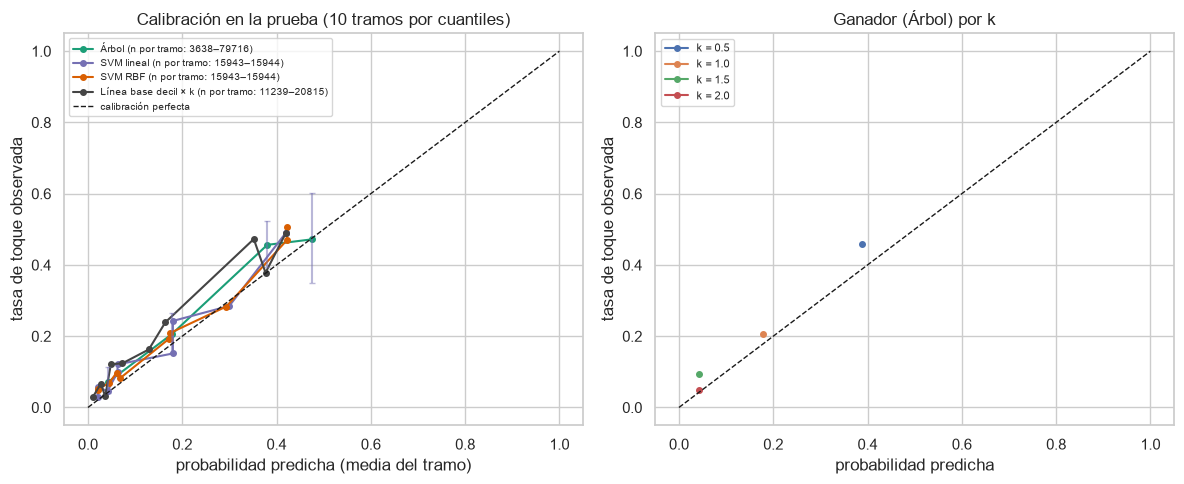

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
ax = axs[0]
for nom, c in (("arbol", "#1b9e77"), ("lineal", "#7570b3"), ("rbf", "#d95f02"), ("linea_base", "#444444")):
    t = cal[nom]; ax.plot(t["p_media"], t["tasa_obs"], "o-", color=c, ms=4, label=f"{nombres[nom]} (n por tramo: {int(t['n'].min())}–{int(t['n'].max())})")
t = cal[GANADOR_ALG]; ax.errorbar(t["p_media"], t["tasa_obs"], yerr=[t["tasa_obs"] - t["ic_lo"], t["ic_hi"] - t["tasa_obs"]], fmt="none", ecolor="#d95f02" if GANADOR_ALG == "rbf" else "#7570b3", alpha=.5, capsize=2)
ax.plot([0, 1], [0, 1], "k--", lw=1, label="calibración perfecta"); ax.set_xlabel("probabilidad predicha (media del tramo)"); ax.set_ylabel("tasa de toque observada")
ax.set_title("Calibración en la prueba (10 tramos por cuantiles)"); ax.legend(fontsize=7)
ax = axs[1]
for k, t in cal_k.items(): ax.plot(t["p_media"], t["tasa_obs"], "o-", ms=4, label=f"k = {k}")
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("probabilidad predicha"); ax.set_ylabel("tasa de toque observada"); ax.set_title(f"Ganador ({NOMBRE[GANADOR_ALG]}) por k"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura.** El **árbol ganador** emite 4 probabilidades distintas (tramos con 79 716, 39 858, 36 220 y 3 638 filas). Predice 0,0418 y observa 0,0702 (IC95 0,0416 a 0,1128); predice 0,1778 y observa 0,2057 (0,1537 a 0,2665); predice 0,3803 y observa 0,4564 (0,3944 a 0,5238, el único donde el IC no contiene la predicción); predice 0,4744 y observa 0,4717 (0,3504 a 0,6025). Observa más de lo que predice en tres de cuatro tramos, y se asocia con que la tasa de la prueba (0,2010) es mayor que la del entrenamiento (0,1706). El error medio de calibración es 3,85 puntos porcentuales (pp). Los dos SVM ponderados siguen la diagonal con 10 tramos: el lineal predice de 0,02 a 0,42 y observa de 0,029 a 0,490 (3,90 pp), y el RBF predice de 0,021 a 0,423 y observa de 0,050 a 0,506 (3,31 pp). La **línea base** predice de 0,01 a 0,42 y observa de 0,029 a 0,489 (4,90 pp). Como el error depende del número de tramos (4 en el árbol, 10 en los otros), no sirve para ordenarlos; sí sirve el diagrama: el árbol, la línea base y los dos SVM siguen la diagonal, con tendencia a observar más de lo predicho. Por k, el árbol tiene un solo valor por k, con errores de 6,88 pp (k = 0,5), 2,79 (1), 5,08 (1,5) y 0,61 (2).

## 8. Puente entre las métricas y los KPI, y cálculo de valor

**Cómo se conectan el AUC, el Brier y la calibración con los KPI.** Son tres preguntas distintas sobre una misma probabilidad: el **AUC** responde si el modelo ordena bien (pone arriba los días que sí tocan), el **Brier** responde cuánto se equivoca la probabilidad (y el BSS cuánto menos que una referencia), y la **calibración** responde si "30 %" significa lo que dice. El producto muestra al inversor una probabilidad con su incertidumbre y la tasa histórica de la línea base; la única parte de esa pantalla que él puede contrastar con su experiencia es si el porcentaje se parece a la frecuencia observada. Por eso la calibración y el BSS frente a la línea base se **asocian** con el KPI 5 (confianza y adopción): informan cuánto debería confiar en la lectura, no cuánto confía. Los KPI 1 a 4 (tiempo de análisis, cambios de pantalla, latencia de los datos, decisiones documentadas) los determinan el diseño del producto y la tarea diaria, no la calidad del modelo; para ellos la tabla lo dice sin forzar un vínculo.

In [20]:
tg = prueba_res[GANADOR_ALG]
puente = [{"kpi": "KPI 5 (confianza y adopción)",
           "metrica": (f"Calibración: error medio entre probabilidad y frecuencia observada = {ece(cal[GANADOR_ALG]) * 100:.1f} pp (prueba). "
                       f"BSS frente a la línea base decil × k = {tg['bss_vs_linea_base']:+.3f} (IC95 {tg['bss_vs_linea_base_ic95'][0]:+.3f} a {tg['bss_vs_linea_base_ic95'][1]:+.3f}); "
                       f"ΔAUC = {delta:+.3f} (IC95 {lo:+.3f} a {hi:+.3f})."),
           "que_no_dice": "No mide si el inversor confía más ni si la lectura cambia su decisión; solo si el porcentaje mostrado se parece a la frecuencia observada y si aporta algo sobre la volatilidad. Se asocia, no se prueba causa."}]
for i, nom in enumerate(["KPI 1 (tiempo de análisis)", "KPI 2 (cambios de pantalla)", "KPI 3 (latencia de los datos)", "KPI 4 (decisiones documentadas)"], 1):
    puente.append({"kpi": nom, "metrica": "Ninguna métrica del modelo; se miden en la sesión 3 y en el registro de la tarea diaria.",
                   "que_no_dice": "El desempeño del modelo no dice nada sobre este KPI."})
tp_ = pd.DataFrame(puente); assert len(tp_) == 5
for r in puente: print(f"{r['kpi']}\n   métrica: {r['metrica']}\n   qué no dice: {r['que_no_dice']}")
res["tabla_puente"] = puente

KPI 5 (confianza y adopción)
   métrica: Calibración: error medio entre probabilidad y frecuencia observada = 3.9 pp (prueba). BSS frente a la línea base decil × k = -0.002 (IC95 -0.009 a +0.003); ΔAUC = -0.018 (IC95 -0.026 a -0.012).
   qué no dice: No mide si el inversor confía más ni si la lectura cambia su decisión; solo si el porcentaje mostrado se parece a la frecuencia observada y si aporta algo sobre la volatilidad. Se asocia, no se prueba causa.
KPI 1 (tiempo de análisis)
   métrica: Ninguna métrica del modelo; se miden en la sesión 3 y en el registro de la tarea diaria.
   qué no dice: El desempeño del modelo no dice nada sobre este KPI.
KPI 2 (cambios de pantalla)
   métrica: Ninguna métrica del modelo; se miden en la sesión 3 y en el registro de la tarea diaria.
   qué no dice: El desempeño del modelo no dice nada sobre este KPI.
KPI 3 (latencia de los datos)
   métrica: Ninguna métrica del modelo; se miden en la sesión 3 y en el registro de la tarea diaria.
   qué no dice:

**Lectura.** La fila del KPI 5 se llena con tres cifras de la prueba: calibración de 3,9 pp, BSS frente a la línea base de −0,002 (IC95 −0,009 a +0,003) y ΔAUC de −0,018 (−0,026 a −0,012). Su lectura es que el porcentaje que ve el inversor se parece a la frecuencia observada (error de 3,9 pp, con tendencia a quedarse corto), pero no aporta nada que la línea base no diga; **la confianza que se puede justificar** es la de una tasa histórica, no la de una predicción. Eso no mide cuánto confía el inversor: eso lo miden los ítems de confianza de la sesión 3. Las cuatro filas restantes no tienen métrica del modelo y la tabla lo dice sin forzar un vínculo.

**Cálculo de valor (matriz de costo y beneficio; solo en este reporte).** Escenario: el inversor deja un **límite de compra** en el nivel de entrada. Se evalúa la regla hipotética "dejar el límite solo cuando la probabilidad es al menos τ". En la matriz: **VP** (dejó el límite y el precio tocó el nivel) = +B, **FP** (lo dejó y no tocó) = −C, y **VN = FN = 0**: no entrar no cuesta ni gana en este escenario. Se usa la unidad C = 1 y B es la razón beneficio/costo. La señal es una por k de la rejilla: τ se fija **por separado para cada k, en validación**, como el valor de la rejilla `[0,10 … 0,50]` que maximiza el neto `B·VP − C·FP` con B/C = 1 (a igual neto, por ejemplo cuando ninguna señal gana, se toma el τ más alto, el menos activo); la prueba usa ese τ y no lo vuelve a tocar. Como el beneficio y el costo del inversor son inciertos, **no se elige un punto**: se presenta la sensibilidad para razones de 0,5 a 3 (y, si ya existe, el rango de la sesión 2 marcado aparte). τ y "compra" **no aparecen en el producto**.

**Condición de equilibrio.** Con B = C, la regla no pierde si `recall / fall-out ≥ (1 − p) / p`, donde `p` es la tasa de toque (recall: fracción de los toques que la regla captura; fall-out: fracción de los no toques que la regla marca por error). En lenguaje del inversor: **cuántas veces más debe acertar de lo que se equivoca** para no perder.

In [21]:
# Matriz costo/beneficio (reporte): señal "toca el nivel" = p ≥ τ. VP = +B, FP = −C, VN = FN = 0 (no entrar no cuesta ni gana: es un límite de compra).
# Unidad: C = 1; B = razón beneficio/costo.
p_ent_global = ref_ent["p0"]                                   # entrenamiento (2010–2014, solo lo conocido en t)
p_glob = float(tabla["y"].mean()); p_pru = float(pt["y"].mean())
eq = {"entrenamiento": p_ent_global, "global": p_glob, "prueba": p_pru}
print("Condición de equilibrio con B = C:  recall / fall-out ≥ (1 − p) / p   (cuántas veces más debe acertar de lo que se equivoca para no perder)")
for nom, p in eq.items(): print(f"   p = {p:.4f} ({nom}) → recall/fall-out ≥ {(1 - p) / p:.2f}")
equilibrio = {"p": eq, "exigido": {n: (1 - p) / p for n, p in eq.items()}}
# Mismo cálculo por k (la tasa cambia mucho con k) con la tasa del entrenamiento
equilibrio["exigido_por_k_entrenamiento"] = {str(k): float((1 - v) / v) for k, v in ref_ent["tasa_k"].items()}
print("   por k (tasa del entrenamiento):", {k: round(v, 2) for k, v in equilibrio["exigido_por_k_entrenamiento"].items()})
rango = cm.RAIZ / "docs" / "entrega_2" / "12_sesiones" / "razon_beneficio_costo.json"
rango_s2 = json.load(open(rango)) if rango.exists() else None
razones = [(str(r), r) for r in RAZON_BC] + ([(f"sesión 2 · {n}", rango_s2[n]) for n in ("min", "central", "max")] if rango_s2 else [])
print("\nrango de la sesión 2:", rango_s2 if rango_s2 else "no existe todavía (se usa la sensibilidad de 0,5 a 3)")

Condición de equilibrio con B = C:  recall / fall-out ≥ (1 − p) / p   (cuántas veces más debe acertar de lo que se equivoca para no perder)
   p = 0.1435 (entrenamiento) → recall/fall-out ≥ 5.97
   p = 0.1882 (global) → recall/fall-out ≥ 4.31
   p = 0.2010 (prueba) → recall/fall-out ≥ 3.98
   por k (tasa del entrenamiento): {'0.5': 1.59, '1.0': 6.12, '1.5': 24.16, '2.0': 121.72}

rango de la sesión 2: no existe todavía (se usa la sensibilidad de 0,5 a 3)


In [22]:
def valor(df, col, k, tau, r):
    d = df[df.k == k]; y = d["y"].to_numpy(); s = d[col].to_numpy() >= tau
    vp, fp = int((s & (y == 1)).sum()), int((s & (y == 0)).sum()); neto = r * vp - fp          # en unidades de C
    rec = vp / max(int((y == 1).sum()), 1); fo = fp / max(int((y == 0).sum()), 1)
    return {"k": str(k), "tau": tau, "razon": r, "vp": vp, "fp": fp, "n_senales": vp + fp, "n_filas": len(d), "neto": float(neto),
            "neto_por_fila": float(neto / len(d)), "neto_por_senal": float(neto / (vp + fp)) if vp + fp else None,
            "recall": rec, "fall_out": fo, "recall_sobre_fallout": float(rec / fo) if fo > 0 else None}

# τ por k, en VALIDACIÓN, con B/C = 1: el valor de la rejilla que maximiza el neto (B·VP − C·FP) de la señal de ese k.
GAN_V = gg["id"]                                                # columna de la validación del ganador (modelo entrenado con 2010–2014)
tau_k, filas_v = {}, []
for k in cm.K_GRID:
    cand = [valor(pv, GAN_V, k, t, 1.0) for t in TAU_REJILLA]
    mejor = max(cand, key=lambda c: (c["neto"], c["tau"])); tau_k[str(k)] = mejor["tau"]   # a igual neto (p. ej. ninguna señal), el τ más alto: el menos activo
print("τ por k elegido en validación (B/C = 1):", tau_k)
sens_v = [valor(pv, GAN_V, k, t, r) | {"etiqueta_razon": e} for k in cm.K_GRID for t in TAU_REJILLA for e, r in razones]
sens_p = [valor(pt, GAN, k, t, r) | {"etiqueta_razon": e} for k in cm.K_GRID for t in TAU_REJILLA for e, r in razones]
base_p = [valor(pt, "p_base", k, tau_k[str(k)], r) | {"etiqueta_razon": e} for k in cm.K_GRID for e, r in razones]
for nom, sens in (("VALIDACIÓN", sens_v), ("PRUEBA", sens_p)):
    d = pd.DataFrame(sens)
    for k in cm.K_GRID:
        t = d[d.k == str(k)].pivot(index="tau", columns="etiqueta_razon", values="neto_por_fila") * 1000
        t = t[[e for e, _ in razones]]; t.insert(0, "señales", d[(d.k == str(k)) & (d.etiqueta_razon == "1.0")].set_index("tau")["n_senales"])
        print(f"\n{nom} · k = {k} · valor neto por cada 1 000 filas (unidades de C), por razón B/C  (τ elegido en validación para este k: {tau_k[str(k)]})")
        print(t.round(1).to_string())
# Resumen en la prueba con el τ de cada k, B/C = 1: ganador frente a la línea base decil × k con el mismo τ
rs = []
for k in cm.K_GRID:
    g = valor(pt, GAN, k, tau_k[str(k)], 1.0); b = valor(pt, "p_base", k, tau_k[str(k)], 1.0)
    rs.append({"k": k, "τ": tau_k[str(k)], "señales ganador": g["n_senales"], "VP": g["vp"], "FP": g["fp"], "neto/1000 filas": g["neto_por_fila"] * 1000,
               "recall/fall-out": g["recall_sobre_fallout"], "exigido (p entren. del k)": equilibrio["exigido_por_k_entrenamiento"][str(k)],
               "señales base": b["n_senales"], "neto/1000 base": b["neto_por_fila"] * 1000})
print("\nPrueba, B/C = 1, τ de validación por k:"); print(pd.DataFrame(rs).round(3).to_string(index=False))
res["valor"] = {"escenario": "límite de compra en el nivel; VP = +B, FP = −C, VN = FN = 0; unidad C = 1", "equilibrio": equilibrio, "tau_por_k_validacion": tau_k,
                "razones": [e for e, _ in razones], "rango_sesion_2": rango_s2,
                "sensibilidad": {"validacion": sens_v, "prueba": sens_p}, "linea_base_prueba_tau_validacion": base_p}

τ por k elegido en validación (B/C = 1): {'0.5': 0.4, '1.0': 0.5, '1.5': 0.5, '2.0': 0.5}



VALIDACIÓN · k = 0.5 · valor neto por cada 1 000 filas (unidades de C), por razón B/C  (τ elegido en validación para este k: 0.4)
etiqueta_razon  señales       0.5      1.0      1.5      2.0      3.0
tau                                                                  
0.1000            19866 -285.7000 -47.6000 190.5000 428.6000 904.8000
0.1500            19866 -285.7000 -47.6000 190.5000 428.6000 904.8000
0.2000            19866 -285.7000 -47.6000 190.5000 428.6000 904.8000
0.2500            19866 -285.7000 -47.6000 190.5000 428.6000 904.8000
0.3000            19866 -285.7000 -47.6000 190.5000 428.6000 904.8000
0.4000             7033  -53.5000  46.7000 146.8000 247.0000 447.3000
0.5000                0    0.0000   0.0000   0.0000   0.0000   0.0000

VALIDACIÓN · k = 1.0 · valor neto por cada 1 000 filas (unidades de C), por razón B/C  (τ elegido en validación para este k: 0.5)
etiqueta_razon  señales       0.5       1.0       1.5       2.0       3.0
tau                               

**Lectura.** *Equilibrio:* con B = C, la regla debe acertar al menos 5,97 veces más de lo que se equivoca con la tasa del entrenamiento (0,1435), 4,31 con la global (0,1882) y 3,98 con la de prueba (0,2010); por k exige 1,59 (k = 0,5), 6,12 (1), 24,16 (1,5) y 121,72 (2), porque cuanto más raro el toque, más precisa debe ser la señal. *τ en validación (B/C = 1):* k = 0,5 → 0,40 (+46,7 por 1 000 filas en validación); para k = 1, 1,5 y 2 el árbol nunca llega a 0,5 y los τ más bajos pierden o no emiten, así que gana el τ más alto (ninguna señal). *Prueba con ese τ:* con k = 0,5 y τ = 0,40 hay 3 638 señales (1 716 acertadas y 1 922 no) y el neto es −5,2 por 1 000 filas con B/C = 1; acierta 1,06 veces más de lo que se equivoca y se exige 1,59. Sensibilidad en ese caso: −26,7, −5,2, +16,4, +37,9 y +80,9 por 1 000 filas para razones de 0,5, 1, 1,5, 2 y 3; el neto cruza 0 con una razón B/C de 1,12 (1 922 / 1 716). Con τ = 0,10 (señal en todas las filas de k = 1) el neto es negativo para todas las razones de 0,5 a 3 (de −691,4 a −177,1 por 1 000 filas), porque con tasa de 0,2057 una señal permanente no cubre su costo. La línea base con los mismos τ da un neto parecido (k = 0,5: −4,3 por 1 000 filas con 7 791 señales). No hay una regla de valor positivo y robusta con B/C ≤ 1 y no se elige un punto: depende de la razón beneficio/costo que estime el inversor. Esto es otra razón para que la lectura sea informativa.

## 9. Evaluación cualitativa

**(a) SVM lineal y (b) árbol.** Se muestran aunque no ganen: sus coeficientes e importancias dicen qué variables empujan la probabilidad (I p.12–17).

In [23]:
nom_var = {"abs_r": "|r_t| (magnitud del último retorno)", "sigma20_sigma252": "σ20/σ252 (aceleración de la volatilidad)", "sigma252": "σ252 (volatilidad del último año)", "k": "k (distancia del nivel, en σ·√N)"}
lin = finales["lineal"]["modelo"]
coef = pd.Series(lin.coef_[0], index=VARS)
print(f"(a) SVM lineal reentrenado (C = {ganador['lineal']['hiperparametros']['C']}); coeficientes en unidades estandarizadas (signo + = empuja hacia 'toca el nivel'):")
print(pd.DataFrame({"coeficiente": [f"{v:.3e}" for v in coef], "relativo al mayor |coef|": (coef / coef.abs().max()).round(3), "variable": [nom_var[v] for v in VARS]}, index=VARS).to_string())
print(f"intercepto = {lin.intercept_[0]:.4f} · filas con puntaje de la frontera > 0 en el reentrenamiento: {(finales['lineal'].decision_function(fin_sub[VARS]) > 0).mean():.4f}")
arb = finales["arbol"]["modelo"]
imp = pd.Series(arb.feature_importances_, index=VARS)
print(f"\n(b) Árbol reentrenado {ganador['arbol']['hiperparametros']}: importancia de variables (suma 1)")
print(pd.DataFrame({"importancia": imp, "variable": [nom_var[v] for v in VARS]}).to_string())
print("\nregla del árbol (variables en unidades estandarizadas):"); print(export_text(arb, feature_names=VARS, decimals=2, max_depth=3))
res["cualitativo"] = {"coef_lineal": coef.to_dict(), "coef_lineal_relativo": (coef / coef.abs().max()).to_dict(), "importancia_arbol": imp.to_dict()}

(a) SVM lineal reentrenado (C = 0.01); coeficientes en unidades estandarizadas (signo + = empuja hacia 'toca el nivel'):
                 coeficiente  relativo al mayor |coef|                                  variable
abs_r             -1.515e-05                   -0.0000       |r_t| (magnitud del último retorno)
sigma20_sigma252  -6.546e-06                   -0.0000  σ20/σ252 (aceleración de la volatilidad)
sigma252          -5.988e-05                   -0.0000         σ252 (volatilidad del último año)
k                 -1.118e+00                   -1.0000          k (distancia del nivel, en σ·√N)


intercepto = -0.5001 · filas con puntaje de la frontera > 0 en el reentrenamiento: 0.2920

(b) Árbol reentrenado {'max_depth': 2, 'min_samples_leaf': 2000}: importancia de variables (suma 1)
                  importancia                                  variable
abs_r                  0.0000       |r_t| (magnitud del último retorno)
sigma20_sigma252       0.0000  σ20/σ252 (aceleración de la volatilidad)
sigma252               0.0221         σ252 (volatilidad del último año)
k                      0.9779          k (distancia del nivel, en σ·√N)

regla del árbol (variables en unidades estandarizadas):
|--- k <= -0.89
|   |--- sigma252 <= -0.38
|   |   |--- class: 0
|   |--- sigma252 >  -0.38
|   |   |--- class: 0
|--- k >  -0.89
|   |--- k <= 0.00
|   |   |--- class: 0
|   |--- k >  0.00
|   |   |--- class: 0



**Lectura.** *(a) SVM lineal (C = 0,01), con pesos de clase:* el coeficiente estandarizado de k es −1,118 y los de las otras tres variables son del orden de 10⁻⁵ (|r_t| −1,5·10⁻⁵, σ20/σ252 −6,5·10⁻⁶, σ252 −6,0·10⁻⁵); el intercepto es −0,5001 y el 29,2 % de las filas del reentrenamiento queda del lado "toca". Se lee: a mayor k (nivel más lejano), menor probabilidad, como se espera, y **las variables de volatilidad casi no pesan** (con C = 0,01 la regularización es fuerte, y el árbol y la línea base coinciden en que aportan poco). *(b) Árbol (profundidad 2, hojas de 2 000):* la importancia es 0,9779 para k y 0,0221 para σ252; |r_t| y σ20/σ252 valen 0. La regla (con variables estandarizadas) separa primero k = 0,5 del resto; con k = 0,5 usa σ252 para dar 0,4744 (volatilidad baja) o 0,3803 (volatilidad alta: se asocia más toque cuando la volatilidad previa es baja, porque k ya está medido en unidades de σ); con k = 1 da 0,1778 y con k = 1,5 y 2 da 0,0418. Es decir, **el modelo es casi una tabla por k**, y los dos modelos interpretables dicen lo mismo: lo que explica la probabilidad es k. Eso explica por qué no supera la línea base.

**(c) ICE del RBF.** Las curvas de expectativa condicional individual (ICE, I p.20–24) muestran cómo cambia la probabilidad de cada fila al mover una variable, y se calculan solo si el RBF es el ganador global.

In [24]:
# (c) ICE (curvas por observación, I p.20–24) solo si el RBF es el ganador global.
if GANADOR_ALG == "rbf":
    mod = finales["rbf"]; muestra = pt.sample(150, random_state=cm.SEMILLA)
    rejilla = np.linspace(pt["sigma252"].quantile(.02), pt["sigma252"].quantile(.98), 25)
    fig, ax = plt.subplots(figsize=(7, 4))
    for _, fila in muestra.iterrows():
        X = pd.DataFrame([fila[VARS].to_dict()] * len(rejilla)); X["sigma252"] = rejilla
        pr = mod.predict_proba(X[VARS])[:, 1]; ax.plot(rejilla, pr - pr[0], color="#d95f02", alpha=.12)      # ICE centrado en el primer punto
    ax.set_xlabel("σ252 diaria"); ax.set_ylabel("cambio de la probabilidad respecto al primer punto"); ax.set_title("ICE centrado del RBF para σ252 (150 filas de la prueba)")
    plt.tight_layout(); plt.show()
else:
    print(f"(c) El RBF no es el ganador global (gana {NOMBRE[GANADOR_ALG]}); no se calcula el ICE.")

(c) El RBF no es el ganador global (gana Árbol); no se calcula el ICE.


**Lectura.** El SVM RBF no es el ganador global (en validación su BSS medio es 0,1668 y queda a 0,0031 del mejor, y en la prueba su AUC es 0,7681 con un ΔAUC frente a la línea base de −0,0030, IC95 −0,0102 a +0,0036), así que no se calcula el ICE: el ICE explica un modelo que se va a usar, y este no lo es.

**(d) Errores por año y por ticker.** Dónde se equivoca más el ganador, con el BSS frente a la línea base del mismo grupo.

In [25]:
# (d) Errores por año y por ticker del ganador en la prueba. BSS frente a la línea base decil × k del mismo grupo.
por_t = pd.DataFrame([{"ticker": t, "Brier": brier(g["y"], g[GAN]), "Brier base": brier(g["y"], g["p_base"]), "BSS vs base": cm.brier_skill(g["y"], g[GAN], g["p_base"].to_numpy()),
                       "AUC": auc(g["y"], g[GAN]), "tasa": g["y"].mean()} for t, g in pt.groupby("ticker")]).sort_values("BSS vs base")
por_a = pd.DataFrame([{"año": a, "Brier": brier(g["y"], g[GAN]), "Brier base": brier(g["y"], g["p_base"]), "BSS vs base": cm.brier_skill(g["y"], g[GAN], g["p_base"].to_numpy()),
                       "AUC": auc(g["y"], g[GAN]), "tasa": g["y"].mean()} for a, g in pt.groupby("anio")]).sort_values("BSS vs base")
print("Peores 3 tickers (BSS vs línea base):"); print(por_t.head(3).to_string(index=False))
print("Mejores 3 tickers:"); print(por_t.tail(3).to_string(index=False))
print("\nPor año de prueba (de peor a mejor BSS vs línea base):"); print(por_a.to_string(index=False))
print(f"\ntickers con BSS vs base > 0: {int((por_t['BSS vs base'] > 0).sum())} de {len(por_t)} · años con BSS vs base > 0: {int((por_a['BSS vs base'] > 0).sum())} de {len(por_a)}")
res["errores"] = {"por_ticker": por_t.set_index("ticker").to_dict("index"), "por_anio": por_a.set_index("año").rename(index=str).to_dict("index")}

Peores 3 tickers (BSS vs línea base):
ticker  Brier  Brier base  BSS vs base    AUC   tasa
   WMT 0.1051      0.1028      -0.0222 0.7438 0.1328
   PEP 0.1334      0.1310      -0.0186 0.7531 0.1928
   SYY 0.1265      0.1252      -0.0108 0.7661 0.1841
Mejores 3 tickers:
ticker  Brier  Brier base  BSS vs base    AUC   tasa
   CAG 0.1646      0.1656       0.0061 0.7671 0.2558
   TSN 0.1494      0.1506       0.0082 0.7538 0.2235
   STZ 0.1584      0.1602       0.0110 0.7624 0.2430

Por año de prueba (de peor a mejor BSS vs línea base):
 año  Brier  Brier base  BSS vs base    AUC   tasa
2020 0.1510      0.1479      -0.0209 0.6552 0.1968
2021 0.0854      0.0841      -0.0159 0.8257 0.1109
2023 0.1504      0.1497      -0.0052 0.7295 0.2175
2019 0.1007      0.1009       0.0018 0.7768 0.1329
2024 0.1356      0.1358       0.0018 0.7737 0.2043
2022 0.1841      0.1851       0.0053 0.7637 0.2905
2026 0.1578      0.1592       0.0085 0.7598 0.2406
2025 0.1441      0.1454       0.0085 0.8041 0.2330

tic

**Lectura.** Por acción, el BSS del árbol frente a la línea base es positivo en 8 de 21 y va de −0,0222 (WMT), −0,0186 (PEP) y −0,0108 (SYY) a +0,0061 (CAG), +0,0082 (TSN) y +0,0110 (STZ). Por año es positivo en 5 de 8: los peores son 2020 (−0,0209; AUC 0,6552, el más bajo), 2021 (−0,0159) y 2023 (−0,0052). Las diferencias son de uno o dos puntos de BSS: el árbol y la línea base se parecen en todas partes y el árbol no falla en un lugar concreto.

**(e) Oportunidades de mejora.** (1) Variables que faltan: el modelo solo usa magnitud y k (los siete indicadores se descartaron en la entrega 1) y ninguna variable de contexto de mercado (dependencia del sector). (2) k continuo: hoy se entrena con 4 valores de k y la API usa el más cercano. (3) La submuestra usa una de cada cinco filas; se podría comparar con todas las filas (más lento para el SVM). (4) Una sensibilidad sin solapamiento (una fila cada 60 sesiones) no se corrió; el bootstrap por bloques ya trata el solapamiento en el IC, pero no en el ajuste. (5) La selección se apoya en solo 4 años de validación y 6 combinaciones separadas por menos de 0,005, así que su varianza es alta. (6) Los SVM ya usan pesos de clase; una regresión logística con k continuo sería una referencia más simple (fuera de las tres técnicas de este plan).

**(f) Envejecimiento.** El modelo se entrena una sola vez con 2009–2018 y el mercado cambia (la tasa de toque pasa de 0,1706 en el entrenamiento a 0,2010 en la prueba y de 0,1109 en 2021 a 0,2905 en 2022), así que hay que reevaluarlo con la prueba por año antes de confiar en él con datos nuevos.

**Referencias de apoyo (FPP3, Hyndman y Athanasopoulos).** *Bloques de semanas:* el libro remuestrea bloques de semanas para conservar la dependencia en el tiempo; aquí el mismo principio se aplica con bloques de 60 fechas diarias. *Ex-ante frente a ex-post:* el modelo se evalúa como si estuviéramos en cada fecha, solo con datos hasta t (ex-ante), no con información que se conoce después. *Eficiencia de mercado:* el libro la discute para niveles de precio, no para probabilidades de toque, así que aquí es solo una cautela: que el modelo no supere la línea base es compatible con esa idea, pero este notebook no la prueba.

## 10. Modelo guardado

El ganador global reentrenado con 2009–2018 se guarda en `app/modelo/modelo.joblib` y su descripción en `app/modelo/metadata.json`: algoritmo, hiperparámetros, variables, `k_grid` (la API usa el k más cercano si el nivel del usuario cae fuera de la rejilla y lo avisa), cortes de decil de σ252, tasas de referencia (también por decil y k), la tabla de calibración con IC95 y las métricas de prueba. Se comprueba el tamaño (la API lo cargará en un servidor con 512 MB) y que la recarga en un **proceso nuevo** da las mismas probabilidades.

In [26]:
# --- app/modelo: ganador global reentrenado con 2009–2018 ---
modelo_final = finales[GANADOR_ALG]
ruta_m = cm.DIR_MODELO / "modelo.joblib"
joblib.dump(modelo_final, ruta_m, compress=3)
tabla_dk = {str(k): ref_fin["tab"][k].round(6).tolist() for k in cm.K_GRID}          # 10 tasas (deciles 1 a 10 de σ252) por k
cal_meta = [{"tramo_lo": float(r.tramo_lo), "tramo_hi": float(r.tramo_hi), "tasa_obs": float(r.tasa_obs), "ic_lo": float(r.ic_lo), "ic_hi": float(r.ic_hi), "n": int(r.n)}
            for r in cal[GANADOR_ALG].itertuples()]
meta = {"algoritmo": GANADOR_ALG, "hiperparametros": gg["hiperparametros"], "variables": VARS, "k_grid": list(cm.K_GRID), "k_sup": cm.K_SUP, "n": cm.N_DIAS,
        "fecha_entrenamiento": str(fin["fecha"].max().date()), "ventana_entrenamiento": [str(fin["fecha"].min().date()), str(fin["fecha"].max().date())],
        "cortes_decil_sigma": ref_fin["cortes"][1:-1].tolist(),                       # 9 cortes interiores de σ252 diaria; los extremos están abiertos
        "tasa_ref": {str(k): float(v) for k, v in ref_fin["tasa_k"].items()},
        "tasa_ref_por_decil_k": tabla_dk, "calibracion_prueba": cal_meta, "linea_base": tabla_dk, "version_sklearn": sklearn.__version__,
        "metricas_prueba": {"auc": tg["auc"], "auc_ic95": tg["auc_ic95"], "brier": tg["brier"], "bss": tg["bss"], "bss_ic95": tg["bss_ic95"],
                            "bss_vs_linea_base": tg["bss_vs_linea_base"], "bss_vs_linea_base_ic95": tg["bss_vs_linea_base_ic95"],
                            "auc_linea_base": prueba_res["linea_base"]["auc"], "delta_auc": delta, "delta_auc_ic95": [lo, hi],
                            "decision_negocio": dec_neg, "decision_estadistica": dec_est, "lectura": "informativa" if dec_neg != "accionable" else "accionable"}}
(cm.DIR_MODELO / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=1, default=jdefault), encoding="utf-8")
mb = ruta_m.stat().st_size / 1e6
print(f"modelo.joblib: {mb:.3f} MB (límite de este proyecto: 25 MB; Render tiene 512 MB) · scikit-learn {sklearn.__version__}")
assert mb < 25 and len(meta["tasa_ref_por_decil_k"]["1.0"]) == 10 and len(cal_meta[0]) == 6
print("claves de calibracion_prueba[0]:", list(cal_meta[0]), "· deciles en tasa_ref_por_decil_k['1.0']:", len(meta["tasa_ref_por_decil_k"]["1.0"]))

# Recarga en un proceso NUEVO: las 5 predicciones deben coincidir con las del notebook
muestra5 = prueba.sample(5, random_state=cm.SEMILLA)
with tempfile.TemporaryDirectory() as td:
    muestra5[VARS].to_csv(f"{td}/X.csv", index=False, float_format="%.17g")
    codigo = ("import sys, joblib, numpy as np, pandas as pd; m = joblib.load(sys.argv[1]); X = pd.read_csv(sys.argv[2]); "
              "np.save(sys.argv[3], m.predict_proba(X)[:, 1])")
    subprocess.run([sys.executable, "-c", codigo, str(ruta_m), f"{td}/X.csv", f"{td}/p.npy"], check=True)
    p_nuevo = np.load(f"{td}/p.npy")
p_nb = modelo_final.predict_proba(muestra5[VARS])[:, 1]
print("proceso nuevo:", np.round(p_nuevo, 6), "\nnotebook:     ", np.round(p_nb, 6), "\nnp.allclose:", bool(np.allclose(p_nuevo, p_nb)))
assert np.allclose(p_nuevo, p_nb)
res["modelo_guardado"] = {"tamano_mb": mb, "version_sklearn": sklearn.__version__, "recarga_coincide": True}

modelo.joblib: 0.001 MB (límite de este proyecto: 25 MB; Render tiene 512 MB) · scikit-learn 1.9.1
claves de calibracion_prueba[0]: ['tramo_lo', 'tramo_hi', 'tasa_obs', 'ic_lo', 'ic_hi', 'n'] · deciles en tasa_ref_por_decil_k['1.0']: 10


proceso nuevo: [0.041788 0.041788 0.380343 0.041788 0.177843] 
notebook:      [0.041788 0.041788 0.380343 0.041788 0.177843] 
np.allclose: True


**Lectura.** `modelo.joblib` pesa 0,001 MB (unos 1,4 KB, muy por debajo del límite de 25 MB y de los 512 MB del servidor), está guardado con scikit-learn 1.9.1 (la versión de `uv.lock`) y se recarga en un proceso nuevo con las mismas probabilidades en las 5 filas de control (0,041788, 0,041788, 0,380343, 0,041788 y 0,177843; `np.allclose` verdadero). `metadata.json` trae las 6 claves en cada tramo de calibración y 10 tasas por k en la línea base. Como el ganador emite 4 probabilidades distintas, la API puede mostrar el IC95 del tramo y la tasa de la línea base sin ambigüedad.

## 11. Resultados guardados

In [27]:
res["tiempo_ejecucion_min"] = round((time.time() - T0) / 60, 1)
destino = cm.DIR_RESULTADOS / "nb07.json"
destino.write_text(json.dumps(res, ensure_ascii=False, indent=1, default=jdefault), encoding="utf-8")
print(f"Escrito: {destino.name} — claves: {list(res)}")
print(f"Tiempo total de ejecución del notebook: {res['tiempo_ejecucion_min']} min")

Escrito: nb07.json — claves: ['filas', 'referencias_entrenamiento', 'grillas', 'tasa_toque_validacion_por_anio', 'linea_base', 'seleccion', 'diagnostico_pesos_validacion', 'prueba', 'auc_dentro_de_k', 'supuestos', 'decision_modelo', 'calibracion', 'tabla_puente', 'valor', 'cualitativo', 'errores', 'modelo_guardado', 'tiempo_ejecucion_min']
Tiempo total de ejecución del notebook: 15.1 min


**Resumen de resultados.** (1) *Selección:* 12 combinaciones empatadas; ganó el árbol de profundidad 2 con hojas de 2 000 filas por la regla de simplicidad (BSS medio de validación 0,1674; SVM lineal con C = 0,01, 0,1670; SVM RBF con C = 0,1 y gamma = 0,01, 0,1668). (2) *Prueba:* AUC 0,7529 (árbol), 0,7783 (lineal), 0,7681 (RBF) y 0,7712 (línea base); BSS del árbol 0,1489 frente a la tasa constante y −0,0018 frente a la línea base. (3) *Decisión:* ΔAUC = −0,0183 (IC95 −0,0261 a −0,0120): no se rechaza H0 y no es accionable, así que la lectura técnica es informativa; los otros dos algoritmos tampoco se distinguen de la línea base. (4) *Qué significa:* el AUC y el BSS globales miden sobre todo saber k; dentro de cada k el AUC va de 0,50 a 0,62. (5) *Calibración:* el árbol queda a 3,85 pp de lo observado, con tendencia a quedarse corto en la prueba. (6) *Valor:* sin una regla de valor positivo y robusta con B/C ≤ 1. El tiempo total de ejecución quedó impreso arriba.